# Evolutionary search for new coding algorithms: a runnable demo

**Artifact `art_VhaHGe7SxV95` (iteration 7, claim N).** This is a pre-registered test of whether a **FunSearch / MAP-Elites program search** makes an 8B model write correct **out-of-catalogue (OOC)** algorithms much more often per call than prompt "knobs" do. The search has three parts:

- **Mutator:** Qwen3-8B (bf16, vLLM, temperature 1.0).
- **Evaluator:** a 3-stage sandbox.
- **Novelty critic:** built from 18,237 known code solutions.

The three tasks are memorised LeetCode-style problems: **T2** weighted shortest path, **T03** k-th smallest, and **A3** trapping rain water.

| Arm | What it is |
|---|---|
| **S** | Full search: 4 islands, each a MAP-Elites archive (cell = runtime label × data-structure signature). Each prompt shows 2 parent programs, drawn by a Boltzmann rule over novelty. |
| **NE** | No-evolution ablation: the same prompt, but the parents are frozen to the catalogue references. |
| **I0** | The novelty instruction alone, with no parents. |
| **EAP / BINT** | The best iteration-5 single-sample knobs (enumerate-and-pick; base-model intent). |
| **B0** | Neutral twin prompt. |
| **L** | A larger mutator (qwen3-235b via OpenRouter), 500 calls on T03. |

**Pre-registered prediction:** S ≥ 10× K on ≥ 2 tasks at level a (distinct OOC-screen programs per call), where K is the better of EAP and BINT on each task.

**Result: NOT MET.** The rate ratios R̂ were 3.83 on T2, 6.65 on T03 and 0.91 on A3. Every out-of-catalogue program the search produced is a *known* technique: value-range binary search, Fenwick-tree or treap order statistics, bucket select. The prompt bans the catalogue ("your program must not be any of them"), and the model **substitutes** another textbook algorithm instead of inventing one. No NOVEL algorithm was found.

**What this notebook runs** (CPU only, a few minutes). It runs the original code of `method.py` and `src/*.py`, split into cells, on `mini_demo_data.json`:
1. The pre-registration constants and the sha256 commitment chain (`method.py`, `src/common.py`).
2. The novelty critic (`src/critic.py`), over a mini corpus that holds every nearest neighbour the demo needs, so the published similarities are reproduced **exactly**.
3. The AST pre-screen and the 3-stage sandbox (`src/sandbox.py`, `src/sandbox_runner.py`), with the original unit tests U1, U3, U4 and U5.
4. Commit #1 (`stage_commit1`): the variant band s\* and the budget ladder, from the calibration rows.
5. A **replay** of 99 recorded completions through every step after generation: code extraction, evaluator, critic, labels, the OOC screen, the prompt builder and the MAP-Elites archive.
6. Distinct-program dedup and idea clusters (`src/adjudicate.py`).
7. **Every decisive statistic** in `src/analysis.py`, re-derived from the run's 13,600 per-call outcome records and checked against the published numbers.

**Replayed, not re-run.** These steps need a GPU or paid APIs, so their recorded outputs are used instead, and each place is marked **REPLAY**:
- Qwen3-8B generation on vLLM (about 1 GPU-hour on an RTX A4500);
- the qwen3-235b arm;
- the OpenRouter label-dispute judge;
- the frozen runtime labellers of earlier iterations, which are vendored code not shipped here.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz — NOT on Colab, always install (the versions pinned by the original run)
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- the import blocks of method.py and src/*.py (union, as in the originals) ---
import argparse
import ast
import builtins
import hashlib
import io
import json
import keyword
import math
import os
import random
import re
import resource
import shutil
import statistics
import subprocess
import textwrap
import sys
import threading
import time
import tokenize
import warnings
import zlib
from collections import Counter, defaultdict
from concurrent.futures import Future, ThreadPoolExecutor
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from loguru import logger
from scipy import sparse, stats

# --- notebook additions: inline figures (src/figures.py used matplotlib with the Agg backend) ---
import matplotlib
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/experiment-37/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if not {"examples", "tasks", "full_run"} <= set(data) and Path("mini_demo_data.json").exists():
    # an older copy with a different layout can sit at the URL until the repository is updated
    print("the GitHub copy has a different layout; using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["about"]["artifact"])
print(f"{data['about']['n_examples']} example programs from {data['about']['source_dataset']}")
print(f"full-run outcome records: {data['full_run']['n_calls']} calls; "
      f"mini corpus: {len(data['known_corpus'])} known solutions + the catalogue references")
print({k: len(v) for k, v in data.items()})

the GitHub copy has a different layout; using the local mini_demo_data.json
art_VhaHGe7SxV95 (iteration 7, claim N): evolutionary search for new coding algorithms
99 example programs from search_programs of full_method_out.json (6,274 distinct correct programs)
full-run outcome records: 13600 calls; mini corpus: 55 known solutions + the catalogue references
{'about': 5, 'examples': 99, 'tasks': 3, 'seeds': 3, 'known_corpus': 55, 'calibration': 4, 'archives': 3, 'full_run': 5, 'published': 11}


## Configuration

Every tunable quantity of the demo is set here.

- **`N_PROGRAMS`** is how many recorded calls are replayed through the CPU pipeline. The calls are taken round-robin over task × arm, so even a small number covers every arm. The data file holds 99. The original run generated 13,600 calls live, which needs the GPU.
- **`EVAL_WORKERS`** is the number of sandbox threads. The original used 8 on an 11-vCPU container. Here it is capped at the CPUs available, because every test case runs under a 1 s wall-clock limit (Colab has 2 vCPUs).
- **The statistics knobs** (`PLACEBO_REPS`, `BOOTSTRAP_REPS`) are the repetition counts of the original robustness checks. They are cheap, so they can sit at their original values.
- **`ROOT`** is the folder where the stages write their files. It mirrors the original layout (`inputs/`, `data/`, `predictions/`, `results/`, `figures/`, `commitments.log`).

In [5]:
# ---------------------------------------------------------------- demo scale (tunable)
N_PROGRAMS = 99           # recorded calls replayed through evaluator -> critic -> labels -> OOC screen
                         # (mini_demo_data.json holds 99; the original run generated 13,600 calls live on a GPU)
EVAL_WORKERS = min(8, len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count() or 1)
                         # evaluator threads: the original used 8 on an 11-vCPU container; capped at the CPUs here,
                         # since every test case has a 1 s wall-clock limit that oversubscribing the CPUs would squeeze
PLACEBO_REPS = 200        # arm-shuffle placebo repetitions (original: 200 in analysis.placebo)
BOOTSTRAP_REPS = 2000      # island-cluster bootstrap repetitions (original: 2000 in analysis.island_bootstrap)
MDS_MAX_PROGRAMS = 360    # programs per task in the program-space MDS (original: 360 in figures.f6)
GPU_HOURS = 2.0          # GPU budget for the commit #1 budget ladder (original run: --gpu-hours 2.0)
REPLAY_TASK = "T03"      # task whose replayed S children are fed to the MAP-Elites archive
ROOT = Path("demo_run")  # every file the stages write lands here (the original wrote into the artifact folder)

## 1. Shared helpers (`src/common.py`)

This cell holds the paths, the model and decoding constants, JSON I/O, and `stable_seed`. `stable_seed` is sha256(task|arm|index) mod 2³¹. It was the per-request vLLM seed and seeds every other RNG.

It also holds the **commitment hash chain**. Each line of `commitments.log` holds:
- the sha256 of a committed file;
- the sha256 of the previous line;
- a UTC timestamp.

A committed file may then change only through a new, later commit line.

**Changes from the original:** `ROOT` is the demo folder. The cross-artifact constants (`RUNS_DIR`, the dependency folder, the vendor sources) and the cgroup hardware probes are dropped, because nothing is read from other artifacts here.

In [6]:
ROOT = ROOT.resolve()   # absolute, like the original ROOT = Path(__file__).resolve().parents[1]
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
VENDOR = INPUTS / "vendor"
DATA = ROOT / "data"
RAW = DATA / "raw"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
PRED = ROOT / "predictions"
AUDIT = ROOT / "audit"
LOGS = ROOT / "logs"
COMMITS = ROOT / "commitments.log"
for _d in (INPUTS, VENDOR, DATA, RAW, RESULTS, FIGS, PRED, AUDIT, LOGS, SRC):
    _d.mkdir(parents=True, exist_ok=True)
# notebook addition: the files the stages append to are cleared, so the notebook can be re-run
for _p in [COMMITS, *DATA.glob("rows_*.jsonl")]:
    _p.unlink(missing_ok=True)

# ------------------------------------------------------------------------------------------------ model / decoding
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_ID = "Qwen/Qwen3-8B-Base"
BASE_REV = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"
TEMPERATURE = 1.0
TOP_P = 1.0
MAX_TOKENS = {"T2": 1536, "T03": 1024, "A3": 1024}
VLLM_SEED = 7101
TASKS = ("T2", "T03", "A3")
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
CAP_USD = {"label_disputes": 0.5, "adjudication": 1.8, "L": 1.0, "reserve": 0.2}
CAP_TOTAL_USD = 3.5

ARMS_DECISIVE = ("S", "NE", "I0", "EAP", "BINT", "B0")


# ------------------------------------------------------------------------------------------------ logging
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def trunc(s: Any, n: int = 300) -> str:
    s = str(s)
    return s if len(s) <= n else s[:n] + f"...[+{len(s) - n}]"


# ------------------------------------------------------------------------------------------------ io
def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, default=_json_default))
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
    except ImportError:
        pass
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with p.open() as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping a corrupt line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as f:
        for r in rows:
            f.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def stable_seed(*parts: Any) -> int:
    """sha256(task|arm|index) mod 2^31: the per-request vLLM seed and every external RNG seed."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 31)


def rel(p: Path) -> str:
    """Workspace-relative POSIX path (never an absolute server path in published files)."""
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return Path(p).name


# ------------------------------------------------------------------------------------------------ commitments
def commit(files: list[Path], tag: str, note: str = "") -> str:
    """Hash chain: each line = sha256(file) + sha256(previous line) + UTC (+ tag, file). Returns the last line hash."""
    COMMITS.touch(exist_ok=True)
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()]
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    new = []
    for f in files:
        rec = {"tag": tag, "file": rel(f), "sha256": sha256_file(f), "prev": prev, "utc": utc_now(), "note": note}
        line = json.dumps(rec, sort_keys=True)
        new.append(line)
        prev = sha256_text(line)
    with COMMITS.open("a") as fh:
        for ln in new:
            fh.write(ln + "\n")
    logger.info(f"commit {tag}: {len(files)} file(s), chain head {prev[:12]}")
    return prev


def verify_chain() -> dict[str, Any]:
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()] if COMMITS.exists() else []
    prev = "0" * 64
    ok = True
    bad = []
    for i, ln in enumerate(lines):
        rec = json.loads(ln)
        if rec["prev"] != prev:
            ok = False
            bad.append(i)
        prev = sha256_text(ln)
        f = ROOT / rec["file"]
        if f.exists() and sha256_file(f) != rec["sha256"]:
            # a committed file may only change through a NEW commit line (amendment); the latest line must match
            later = [json.loads(x) for x in lines[i + 1:] if json.loads(x)["file"] == rec["file"]]
            if not later:
                ok = False
                bad.append(i)
    return {"n_lines": len(lines), "ok": ok, "bad_lines": bad, "head": prev}


setup_logging("method_demo")
logger.info(f"demo folder ready: {ROOT.name}/ (seed of T03|S|0 = {stable_seed('T03', 'S', 0)})")

17:26:06|INFO   |demo folder ready: demo_run/ (seed of T03|S|0 = 45052986)


## 2. Pre-registration (`method.py`)

These are the constants of `method.py`, copied verbatim:
- the hypothesis and the falsifiable **prediction**;
- the GPU **budget ladder** (calls per arm at each level, floors, drop order);
- the operational **definitions** (call, correct, OOC screen, distinct, idea cluster, cell, novelty);
- the **tests** and verdict rules;
- the **judge** plan with its prompt and the 10-control gate.

All of them were frozen in **commit #0**, before the first GPU sample.

The verdict rule:

| Verdict | Condition |
|---|---|
| STRONG | LB95 ≥ 10 |
| MET | R̂ ≥ 10 and LB95 > 1 |
| UNRESOLVED | R̂ ≥ 10 and LB95 ≤ 1 |
| NOT MET | R̂ < 10 |
| NOT ESTIMABLE | X_S = X_K = 0 |

Overall MET needs at least 2 tasks MET or STRONG.

In [7]:
HYPOTHESIS = (
    "Claim N (iteration 7, secondary family): a FunSearch / MAP-Elites program search with Qwen3-8B (bf16, thinking "
    "off, vLLM, T 1.0) as the mutator, hidden tests plus fresh randomised stress tests as the evaluator, and a novelty "
    "critic built against the 18,237 known solutions of art_j3Rm_lr2nzR6 produces correct out-of-catalogue programs "
    "at a much higher rate per call than the best single-sample text knobs of iteration 5, on memorised "
    "LeetCode-style tasks with one 8B mutator.")
PREDICTION = ("S >= 10x K on >= 2 tasks: per task the point estimate R_hat = (X_S/N_S)/(X_K/N_K) >= 10 and the exact "
              "conditional Poisson one-sided 95% lower bound LB95 on R above 1, at level a (distinct OOC_screen "
              "programs), K = the better of EAP and BINT per task (max rule). With 2 tasks run, MET needs both.")
LADDER = {
    "level0": {"T2": {"S": 1500, "EAP": 750, "BINT": 750, "NE": 500, "I0": 500, "B0": 200},
               "T03": {"S": 1500, "EAP": 750, "BINT": 750, "NE": 500, "I0": 500, "B0": 200}},
    "level1": {"A3": {"S": 1000, "EAP": 500, "BINT": 500, "NE": 300, "I0": 300, "B0": 100}},
    "level2": "raise S on T03 then T2 in +1000 steps up to 4000 while time allows; K arms >= S/2",
    "level3": "reachability (prompt_logprobs teacher forcing) - optional",
    "level4": "large mutator arm L on T03 via OpenRouter, 500 children, <= USD 1.0 - optional, concurrent",
    "level5": "plan noise - first dropped",
    "floors": {"S": 1000, "EAP": 400, "BINT": 400, "NE": 300, "I0": 300, "B0": 100},
    "drop_order": ["plan_noise", "L (only if OpenRouter binds)", "reachability", "A3", "I0->300,B0->100",
                   "K arms->500", "S->1500->1000 on T2/T03"],
}
DEFINITIONS = {
    "call": "one generated child program (one completion); EAP/BINT count only code-writing calls, their stage-1 GPU "
            "time is charged to their GPU-seconds",
    "correct": "valid (AST pre-screen) AND stage 1 (8 quick cases) AND stage 2 (full hidden suite) AND stage 3 (10 "
               "seeded max-size stress inputs vs the fastest reference)",
    "OOC_screen": "correct AND (final label == 'other' OR nearest-known Jaccard s < s*_task), s*_task = 5th "
                  "percentile of nearest-known similarities of correct forced catalogue programs (label == Y) and "
                  "the references",
    "distinct": "within an arm in call order: identical normalised-token hash merges, then Jaccard >= 0.9 to an earlier "
                "program collapses into it",
    "idea_cluster": "pooled over arms, within each cell (runtime label, DS-signature): single-linkage components at "
                    "Jaccard >= 0.5; after adjudication clusters whose judges named the same algorithm merge",
    "level_a": "distinct OOC_screen programs", "level_b": "distinct adjudicated KNOWN OUTSIDE CATALOGUE + NOVEL",
    "cell": "(runtime label, DS-signature = first 3 of heap, deque_or_queue, sort, bisect, recursion, dict_or_counter, "
            "set, matrix_2d, stack_list, bitops, random, custom_class)",
    "novelty": "nu = 1 - s, s = max token-4-gram Jaccard to corpus + catalogue references (self-match of a seed excluded)",
}
TESTS = {
    "primary": "exact conditional binomial test of two Poisson rates; LB95 from the one-sided Clopper-Pearson bound; "
               "two-sided 95% CI; Holm across tasks",
    "verdict": "STRONG LB95>=10; MET R_hat>=10 & LB95>1; UNRESOLVED R_hat>=10 & LB95<=1; NOT MET R_hat<10; "
               "NOT ESTIMABLE X_S=X_K=0; overall MET if >=2 tasks MET/STRONG",
    "secondary": ["S vs NE", "S vs I0", "NE vs I0", "I0 vs K", "K vs B0", "L vs S (first 500 calls, T03)"],
    "matched_effort": "rarefaction/Chao-1 extrapolation of idea-cluster richness of i.i.d. arms to N_S (trusted to 2x N)",
    "robustness": "island-cluster bootstrap (2,000 reps) of S's rate; arm-shuffle placebo; seeds-as-children check",
    "zero": "rule of three 3/n",
}
JUDGES = {"pair": ["mistralai/mistral-medium-3.1", "moonshotai/kimi-k2-0905"],
          "replacements": ["google/gemini-2.5-flash", "deepseek/deepseek-chat-v3.1", "openai/gpt-4.1-mini"],
          "third": "deepseek/deepseek-chat-v3.1", "temperature": 0, "gate": ">= 9 of 10 controls",
          "label_dispute_judge": "google/gemini-2.5-flash-lite",
          "L_mutator": "qwen/qwen3-235b-a22b-2507", "L_fallback": "qwen/qwen3-coder"}
JUDGE_PROMPT = (
    "You are an expert in algorithms. Decide whether the program below implements a NEW algorithm for a known task.\n\n"
    "TASK\n{spec}\n\nCATALOGUE (the standard known algorithms for this task)\n{catalogue}\n\n"
    "PROGRAM UNDER REVIEW (comments and docstrings removed)\n```python\n{code}\n```\n\n"
    "NEAREST KNOWN SOLUTIONS from a corpus of 18,237 published code solutions (for comparison)\n{nearest}\n\n"
    "SANDBOXED STRESS RESULTS of the program (inputs at three sizes; runtime ratio to the fastest catalogue "
    "reference; log-log slope of runtime against size)\n{stress}\n\n"
    "Classify the program's core algorithm into exactly one class:\n"
    "- NOVEL ALGORITHM: a correct general algorithm whose core mechanism is not in the catalogue and that you cannot "
    "identify as any known published algorithm or textbook technique.\n"
    "- KNOWN OUTSIDE CATALOGUE: a correct general algorithm that is a known, nameable algorithm or textbook technique "
    "not in the catalogue (name it).\n"
    "- CATALOGUE VARIANT: an implementation, restyling or minor modification of a catalogue algorithm (name which).\n"
    "- DEGENERATE: hard-coded or special-cased answers, wrong in general, or brute force that passes only because "
    "the tests are small.\n\n"
    "Answer with JSON only: {{\"class\": \"NOVEL ALGORITHM|KNOWN OUTSIDE CATALOGUE|CATALOGUE VARIANT|DEGENERATE\", "
    "\"named_algorithm\": \"...\", \"core_idea\": \"<one sentence>\", \"confidence\": <0 to 1>, "
    "\"rationale\": \"<at most two sentences>\"}}")
CONTROL_SET_PLAN = [
    "T03 quickselect (Lomuto partition, renamed identifiers) -> CATALOGUE VARIANT",
    "T03 Floyd-Rivest selection -> KNOWN OUTSIDE CATALOGUE",
    "T03 binary search over the value range counting elements <= mid -> KNOWN OUTSIDE CATALOGUE",
    "T03 answer lookup table failing stress -> DEGENERATE",
    "T2 D'Esopo-Pape deque shortest paths -> KNOWN OUTSIDE CATALOGUE",
    "T2 Dijkstra with a hand-written binary-heap class -> CATALOGUE VARIANT",
    "T2 exhaustive simple-path enumeration passing only tiny graphs -> DEGENERATE",
    "A3 sparse-table range-maximum solution -> KNOWN OUTSIDE CATALOGUE",
    "A3 monotonic stack with renamed identifiers -> CATALOGUE VARIANT",
    "A3 decreasing-height processing keeping leftmost/rightmost index -> KNOWN OUTSIDE CATALOGUE",
]

print("PREDICTION:", PREDICTION, "\n")
print("VERDICT RULE:", TESTS["verdict"], "\n")
for k, v in DEFINITIONS.items():
    print(f"  {k:<12} {v}")

PREDICTION: S >= 10x K on >= 2 tasks: per task the point estimate R_hat = (X_S/N_S)/(X_K/N_K) >= 10 and the exact conditional Poisson one-sided 95% lower bound LB95 on R above 1, at level a (distinct OOC_screen programs), K = the better of EAP and BINT per task (max rule). With 2 tasks run, MET needs both. 

VERDICT RULE: STRONG LB95>=10; MET R_hat>=10 & LB95>1; UNRESOLVED R_hat>=10 & LB95<=1; NOT MET R_hat<10; NOT ESTIMABLE X_S=X_K=0; overall MET if >=2 tasks MET/STRONG 

  call         one generated child program (one completion); EAP/BINT count only code-writing calls, their stage-1 GPU time is charged to their GPU-seconds
  correct      valid (AST pre-screen) AND stage 1 (8 quick cases) AND stage 2 (full hidden suite) AND stage 3 (10 seeded max-size stress inputs vs the fastest reference)
  OOC_screen   correct AND (final label == 'other' OR nearest-known Jaccard s < s*_task), s*_task = 5th percentile of nearest-known similarities of correct forced catalogue programs (label == Y) a

## 3. Inputs: the three task objects (`method.py --stage inputs`, `src/inputs.py`)

The original `inputs` stage vendored the frozen benches of earlier iterations, read-only and with sha256s, and assembled one object per task. Each object holds:
- the verbatim spec;
- the **catalogue** of standard algorithms, which is what "out of catalogue" means;
- the reference implementations and the seed reference per mode;
- the hidden test suite, split into the 8 **quick** cases and the **rest**;
- 10 seeded maximum-size **stress** inputs, whose expected outputs come from the fastest reference.

Here the assembled objects come from `mini_demo_data.json` and are written to the same `inputs/tasks/` layout. `load_task` is the original function.

In [8]:
TASK_DIR = INPUTS / "tasks"
# notebook replacement of `method.py --stage inputs`: the assembled task objects come from mini_demo_data.json
for _t, _obj in data["tasks"].items():
    write_json(TASK_DIR / f"{_t}.json", _obj, indent=None)


def load_task(task: str) -> dict[str, Any]:
    return read_json(TASK_DIR / f"{task}.json")


def cases_for_display(task_obj: dict[str, Any]) -> dict[str, Any]:
    return {"n_quick": len(task_obj["stages"]["quick"]), "n_rest": len(task_obj["stages"]["rest"]),
            "n_stress": len(task_obj["stages"]["stress"])}


for t in TASKS:
    o = load_task(t)
    print(f"{t}: {o['signature']}  default mode = {o['default']}  stages = {cases_for_display(o)}  "
          f"fastest reference = {o['fastest_ref']} ({o['fastest_ref_stress_s'] * 1000:.2f} ms over the stress inputs)")
    for c in o["catalogue"]:
        print(f"      catalogue {c['mode']:<18} {c['display_name']}")
print("\nT03 spec:", load_task("T03")["spec_body"])

T2: solve(n, edges, s, t)  default mode = dijkstra  stages = {'n_quick': 8, 'n_rest': 37, 'n_stress': 10}  fastest reference = dijkstra_lazy (1.40 ms over the stress inputs)
      catalogue dijkstra           Dijkstra's algorithm
      catalogue bf_spfa            Bellman-Ford (including its queue-based form SPFA)
      catalogue bidijkstra         bidirectional Dijkstra
      catalogue floyd              Floyd-Warshall
      catalogue dial               Dial's algorithm (bucket queue)
T03: solve(nums, k)  default mode = full_sort  stages = {'n_quick': 8, 'n_rest': 52, 'n_stress': 10}  fastest reference = full_sort (0.94 ms over the stress inputs)
      catalogue full_sort          a full sort
      catalogue size_k_heap        a size-k heap
      catalogue heapify_pop        heapify-and-pop
      catalogue quickselect        quickselect
      catalogue median_of_medians  median of medians
      catalogue counting_sort      counting sort
A3: solve(height)  default mode = prefix_suffix_

## 4. Novelty critic (`method.py --stage corpus`, `src/critic.py`)

The critic measures how far a program is from everything already known.

1. **Tokenise:** Python `tokenize`. Comments and docstrings are dropped. Identifiers become `ID`, numbers `NUM`, strings `STR`. Keywords, operators, builtins, attribute names and imported names are kept, as are INDENT/DEDENT.
2. **Shingle:** token 4-grams, hashed (crc32) into 2²² buckets, give one binary row per program.
3. **Score:** s is the **exact sparse Jaccard** similarity to the nearest known program, over the corpus plus the catalogue references, and **novelty ν = 1 − s**.

The original corpus has **18,237** code solutions, rebuilt from the declared dependency `art_j3Rm_lr2nzR6` (LeetCodeDataset, Mercury, KodCode, TheAlgorithms, …). That corpus is too large to ship. Instead, the notebook builds a **mini corpus**: the 20 catalogue references plus the known solutions that are the true nearest neighbours of every program scored below. The build script found those neighbours over the full corpus.

The full-corpus maximum is attained at that neighbour. So the maximum over the mini corpus is the same number, and s and ν come out **exactly** as published. `build_mini_corpus` replaces only the half of `build_corpus` that reads the dependency. The matrix, the AST sequences and the `Critic` class are the original code.

In [9]:
DIM = 1 << 22
SH = 4
CHUNK = 512
TOPK = 50
CORPUS_DIR = DATA / "corpus"
BUILTINS = set(dir(builtins))
# (the iteration-6 corpus-admission tokeniser _toks6/_n_shingles6 is only used while reading the dependency: omitted)


# ------------------------------------------------------------------------------------------------ tokeniser
def _imported_names(code: str) -> set[str]:
    out: set[str] = set()
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return out
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                out.add(a.name.split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            if n.module:
                out.add(n.module.split(".")[0])
            for a in n.names:
                out.add(a.name)
    return out


def norm_tokens(code: str) -> list[str]:
    imported = _imported_names(code)
    raw = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            raw.append(t)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    out: list[str] = []
    prev_sig: str | None = None          # previous significant token (string form)
    line_start = True                    # are we at the start of a logical line?
    i = 0
    n = len(raw)
    while i < n:
        t = raw[i]
        tt = t.type
        if tt in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            i += 1
            continue
        if tt == tokenize.NEWLINE:
            line_start = True
            prev_sig = None
            i += 1
            continue
        if tt in (tokenize.INDENT, tokenize.DEDENT):
            out.append(tokenize.tok_name[tt])
            line_start = True
            i += 1
            continue
        if tt == tokenize.STRING or tt == getattr(tokenize, "FSTRING_START", -1):
            # docstring / string-only statement: a string (or f-string) at line start followed by NEWLINE
            j = i
            if tt != tokenize.STRING:
                while j < n and raw[j].type != getattr(tokenize, "FSTRING_END", -2):
                    j += 1
            k = j + 1
            while k < n and raw[k].type in (tokenize.COMMENT, tokenize.NL):
                k += 1
            if line_start and (k >= n or raw[k].type in (tokenize.NEWLINE, tokenize.ENDMARKER)):
                i = k
                continue
            out.append("STR")
            prev_sig = "STR"
            line_start = False
            i = j + 1
            continue
        if tt == tokenize.NAME:
            s = t.string
            if keyword.iskeyword(s) or keyword.issoftkeyword(s) and s in ("match", "case"):
                out.append(s)
            elif prev_sig == "." or s in BUILTINS or s in imported:
                out.append(s)
            else:
                out.append("ID")
            prev_sig = s
        elif tt == tokenize.NUMBER:
            out.append("NUM")
            prev_sig = "NUM"
        elif tt == tokenize.OP:
            out.append(t.string)
            prev_sig = t.string
        else:
            out.append(tokenize.tok_name.get(tt, "TOK"))
            prev_sig = None
        line_start = False
        i += 1
    return out


def shingle_ids(code: str) -> np.ndarray:
    t = norm_tokens(code)
    if not t:
        return np.zeros(0, dtype=np.int64)
    if len(t) < SH:
        grams = [" ".join(t)]
    else:
        grams = [" ".join(t[i:i + SH]) for i in range(len(t) - SH + 1)]
    return np.unique(np.fromiter((zlib.crc32(g.encode()) % DIM for g in grams), dtype=np.int64, count=len(grams)))


def to_matrix(id_lists: list[np.ndarray]) -> sparse.csr_matrix:
    indptr = np.zeros(len(id_lists) + 1, dtype=np.int64)
    for i, a in enumerate(id_lists):
        indptr[i + 1] = indptr[i] + len(a)
    indices = np.concatenate(id_lists) if id_lists else np.zeros(0, dtype=np.int64)
    data = np.ones(len(indices), dtype=np.float32)
    return sparse.csr_matrix((data, indices.astype(np.int32), indptr), shape=(len(id_lists), DIM))


def jaccard_pair(a: str, b: str) -> float:
    x, y = set(shingle_ids(a).tolist()), set(shingle_ids(b).tolist())
    if not x and not y:
        return 1.0
    return len(x & y) / len(x | y)


# ------------------------------------------------------------------------------------------------ AST sequences
_TYPE_CODE: dict[str, str] = {}


def _code_of_type(name: str) -> str:
    if name not in _TYPE_CODE:
        _TYPE_CODE[name] = chr(0x4E00 + len(_TYPE_CODE))
    return _TYPE_CODE[name]


def ast_seq(code: str) -> str | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return None
    out: list[str] = []
    stack = [tree]
    while stack:
        n = stack.pop()
        name = type(n).__name__
        if name in ("Load", "Store", "Del"):
            continue
        out.append(_code_of_type(name))
        kids = list(ast.iter_child_nodes(n))
        stack.extend(reversed(kids))
    return "".join(out)

In [10]:
def build_mini_corpus(task_objs: dict[str, dict[str, Any]], known: list[dict[str, Any]]) -> dict[str, Any]:
    """Notebook replacement of critic.build_corpus: the corpus rows come from mini_demo_data.json (the nearest
    known solutions of the demo programs) instead of the dependency's full_data_out.json; from the catalogue
    references on, this is the original build_corpus."""
    meta_p = CORPUS_DIR / "meta.jsonl"
    mat_p = CORPUS_DIR / "shingles.npz"
    CORPUS_DIR.mkdir(parents=True, exist_ok=True)
    metas = [{k: v for k, v in m.items() if k != "code"} for m in known]
    codes = [m["code"] for m in known]
    per = Counter(m["dataset"] for m in known)
    n_corpus = len(codes)
    for t, obj in task_objs.items():
        for name, code in obj["references"].items():
            metas.append({"id": f"catalogue:{t}:{name}", "dataset": "catalogue", "row": -1, "field": "reference",
                          "qid": None, "tags": [t], "kind": "catalogue", "mode": obj["ref_mode"][name],
                          "sha": sha256_text(code)[:16], "code_sha256": sha256_text(code)})
            codes.append(code)
    logger.info(f"corpus: {n_corpus} code solutions + {len(codes) - n_corpus} catalogue references; per dataset {dict(per)}")
    ids = [shingle_ids(c) for c in codes]
    M = to_matrix(ids)
    sparse.save_npz(mat_p, M)
    seqs = [ast_seq(c) for c in codes]
    write_jsonl(meta_p, metas)
    write_jsonl(CORPUS_DIR / "codes.jsonl", [{"id": m["id"], "code": c} for m, c in zip(metas, codes)])
    write_json(CORPUS_DIR / "ast_seqs.json", seqs, indent=None)
    write_json(CORPUS_DIR / "type_codes.json", _TYPE_CODE, indent=None)
    pools = {t: sum(1 for m in metas if t in m["tags"] and m["kind"] == "corpus") for t in task_objs}
    summ = {"utc": utc_now(), "n_corpus": n_corpus, "n_catalogue": len(codes) - n_corpus,
            "per_dataset": dict(per), "expected_n_corpus": 18237, "deviation": n_corpus - 18237,
            "same_task_pool_sizes": pools, "dim": DIM, "shingle": SH,
            "nnz_per_row_median": float(np.median(np.diff(M.indptr)))}
    write_json(CORPUS_DIR / "summary.json", summ)
    return summ

In [11]:
class Critic:
    """Nearest-known similarity of programs against corpus + catalogue references."""

    def __init__(self) -> None:
        self.M = sparse.load_npz(CORPUS_DIR / "shingles.npz").tocsr().astype(np.float32)
        self.meta = read_jsonl(CORPUS_DIR / "meta.jsonl")
        self.sizes = np.asarray(self.M.sum(1)).ravel().astype(np.float32)
        tc = read_json(CORPUS_DIR / "type_codes.json")
        _TYPE_CODE.update(tc)
        self.seqs = read_json(CORPUS_DIR / "ast_seqs.json")
        self.MT = self.M.T.tocsr()
        self.cat_sha = {m["code_sha256"]: i for i, m in enumerate(self.meta) if m["kind"] == "catalogue"}
        self._codes: list[str] | None = None

    def code(self, idx: int) -> str:
        if self._codes is None:
            self._codes = [r["code"] for r in read_jsonl(CORPUS_DIR / "codes.jsonl")]
        return self._codes[idx]

    def score(self, codes: list[str], topk: int = TOPK, exclude_self: bool = False) -> list[dict[str, Any]]:
        """exclude_self=True only when scoring the seed references themselves (their identical corpus row)."""
        from rapidfuzz.distance import Levenshtein
        out: list[dict[str, Any]] = []
        for c0 in range(0, len(codes), CHUNK):
            chunk = codes[c0:c0 + CHUNK]
            ids = [shingle_ids(c) for c in chunk]
            P = to_matrix(ids)
            inter = (P @ self.MT).toarray()
            ps = np.array([len(a) for a in ids], dtype=np.float32)
            denom = ps[:, None] + self.sizes[None, :] - inter
            J = np.where(denom > 0, inter / np.maximum(denom, 1e-9), 0.0)
            for r, code in enumerate(chunk):
                row = J[r]
                selfi = self.cat_sha.get(sha256_text(code)) if exclude_self else None
                if selfi is not None:
                    row = row.copy()
                    row[selfi] = -1.0           # exclude the identical self-match of a reference seed
                k = min(topk, len(row))
                top = np.argpartition(-row, k - 1)[:k]
                top = top[np.argsort(-row[top])]
                s = float(max(row[top[0]], 0.0))
                seq = ast_seq(code)
                ad = None
                ad_min = None
                if seq is not None:
                    dists = []
                    for j in top:
                        sj = self.seqs[j]
                        dists.append(Levenshtein.normalized_distance(seq, sj) if sj is not None else 1.0)
                    ad = float(dists[0])
                    ad_min = float(min(dists))
                nm = self.meta[int(top[0])]
                out.append({"s": round(s, 6), "novelty": round(1.0 - s, 6), "nearest_id": nm["id"],
                            "nearest_dataset": nm["dataset"], "nearest_idx": int(top[0]),
                            "top_ids": [int(x) for x in top[:10]], "top_sims": [round(float(row[x]), 4) for x in top[:10]],
                            "ast_dist": ad, "ast_dist_min": ad_min, "n_shingles": int(len(ids[r]))})
        return out

    def nearest_same_task(self, code: str, task: str, k: int = 2) -> list[tuple[int, float]]:
        ids = shingle_ids(code)
        P = to_matrix([ids])
        inter = (P @ self.MT).toarray()[0]
        denom = len(ids) + self.sizes - inter
        J = np.where(denom > 0, inter / np.maximum(denom, 1e-9), 0.0)
        idx = [i for i, m in enumerate(self.meta) if task in m["tags"] and m["kind"] == "corpus"]
        if not idx:
            return []
        idx = np.array(idx)
        order = idx[np.argsort(-J[idx])][:k]
        return [(int(i), float(J[i])) for i in order]


objs = {t: load_task(t) for t in TASKS}
corpus_summary = build_mini_corpus(objs, data["known_corpus"])
critic = Critic()
print("mini corpus:", {k: corpus_summary[k] for k in ("n_corpus", "n_catalogue", "per_dataset")})
print("full corpus of the run:", {k: data["published"]["corpus"][k] for k in ("n_corpus", "n_catalogue")},
      "(n_corpus 18,237 exactly as expected)")

17:26:06|INFO   |corpus: 55 code solutions + 20 catalogue references; per dataset {'leetcodedataset': 4, 'mercury': 5, 'humanevalplus': 1, 'kodcode_algorithmic': 40, 'xlcost_python': 5}


mini corpus: {'n_corpus': 55, 'n_catalogue': 20, 'per_dataset': {'leetcodedataset': 4, 'mercury': 5, 'humanevalplus': 1, 'kodcode_algorithmic': 40, 'xlcost_python': 5}}
full corpus of the run: {'n_corpus': 18237, 'n_catalogue': 20} (n_corpus 18,237 exactly as expected)


In [12]:
# unit test U3 (tests/test_units.py): the critic is invariant to renaming, comments and docstrings
def test_u3_critic_invariances():
    p = "import heapq\n\ndef solve(nums, k):\n    h = list(nums)\n    heapq.heapify(h)\n    for _ in range(k - 1):\n        heapq.heappop(h)\n    return h[0]\n"
    r = p.replace("h", "zz").replace("zzeapq", "heapq").replace("zzeappop", "heappop").replace("zzeapify", "heapify")
    c = '"""doc"""\n' + p.replace("    h = list(nums)", "    # copy\n    h = list(nums)  # list")
    assert jaccard_pair(p, p) == 1.0
    assert jaccard_pair(p, r) == 1.0
    assert jaccard_pair(p, c) == 1.0


test_u3_critic_invariances()
print("U3 critic invariances (renamed identifiers, comments, docstrings -> Jaccard 1.0): pass")
q = "def solve(nums, k):\n    # sort, then index\n    return sorted(nums)[k - 1]\n"
print("normalised tokens of a one-line full sort:", norm_tokens(q))
sc = critic.score([q])[0]
print(f"its nearest known program: {sc['nearest_id']} with s = {sc['s']:.3f} -> novelty {sc['novelty']:.3f}")

U3 critic invariances (renamed identifiers, comments, docstrings -> Jaccard 1.0): pass
normalised tokens of a one-line full sort: ['def', 'ID', '(', 'ID', ',', 'ID', ')', ':', 'INDENT', 'return', 'sorted', '(', 'ID', ')', '[', 'ID', '-', 'NUM', ']', 'DEDENT']
its nearest known program: catalogue:T03:full_sort with s = 1.000 -> novelty 0.000


## 5. Sandboxed evaluator (`src/sandbox.py`, `src/sandbox_runner.py`) and unit test U1

Every generated program first passes an **AST pre-screen**. The screen rejects:
- banned modules (`os`, `subprocess`, `socket`, …) and banned calls (`open`, `eval`, `exec`, …);
- dunder access;
- literals of more than 64 elements, which could be a lookup table.

The program then runs in a **fresh `python3.12 -I -S` subprocess** under these limits: RLIMIT_AS 2 GiB, RLIMIT_NOFILE 32, RLIMIT_CPU, and a per-case wall alarm. Network and process modules are stubbed out. It goes through three stages and stops at the first failure:

1. 8 quick cases;
2. the rest of the hidden suite;
3. 10 seeded maximum-size **stress** inputs, checked against the fastest reference.

**Correct** means all three stages pass. The runner is the original child script, written to `demo_run/src/`.

Unit test U1 is copied from `tests/test_units.py` and runs here:
- all 20 references pass;
- a program that **hard-codes the hidden answers** passes stages 1–2 but **fails the stress stage**;
- banned code is rejected;
- an endless loop and a 3 GiB allocation are stopped.

In [13]:
# src/sandbox_runner.py, verbatim: the child side of the sandbox (stdlib only, run as `python3.12 -I -S`)
SANDBOX_RUNNER_SRC = r'''"""Child side of the evaluator sandbox (stdlib only; run as `python3.12 -I -S sandbox_runner.py`, job JSON on stdin).

Limits are applied here before the candidate is executed: RLIMIT_AS (address space), RLIMIT_NOFILE, RLIMIT_CPU, and a
per-case wall alarm. Network and process modules are stubbed in sys.modules before exec. Stages run in order and the
run stops at the first failing case. One JSON line per case is flushed to stdout so a killed child still reports
how far it got.
"""

import io
import json
import resource
import signal
import sys
import time

_OUT = sys.stdout


class _Timeout(BaseException):
    pass


def _alarm(signum, frame):
    raise _Timeout()


def emit(obj):
    _OUT.write(json.dumps(obj) + "\n")
    _OUT.flush()


def check(task, expected, output):
    # all three tasks have a unique integer answer
    return isinstance(output, int) and not isinstance(output, bool) and output == expected


def convert(task, kwargs):
    if task == "T2":
        kwargs["edges"] = [tuple(e) for e in kwargs["edges"]]
    return kwargs


def main():
    job = json.loads(sys.stdin.read())
    mem = int(job.get("mem_bytes", 2 * 1024 ** 3))
    resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
    try:
        resource.setrlimit(resource.RLIMIT_NOFILE, (32, 32))
    except (ValueError, OSError):
        pass
    cpu = int(job.get("cpu_s", 60)) + 1
    resource.setrlimit(resource.RLIMIT_CPU, (cpu, cpu + 1))
    for name in ("socket", "_socket", "ssl", "subprocess", "_posixsubprocess", "ctypes", "_ctypes",
                 "multiprocessing", "urllib", "http", "requests", "shutil", "pathlib"):
        sys.modules[name] = None
    signal.signal(signal.SIGALRM, _alarm)
    task = job["task"]
    g = {"__name__": "__candidate__"}
    sink = io.StringIO()
    sys.stdout = sink
    try:
        signal.setitimer(signal.ITIMER_REAL, float(job.get("load_limit", 5.0)))
        exec(compile(job["code"], "<candidate>", "exec"), g)
        signal.setitimer(signal.ITIMER_REAL, 0)
        fn = g.get("solve")
        if not callable(fn):
            raise NameError("no callable solve")
    except _Timeout:
        sys.stdout = _OUT
        emit({"load_error": "load_timeout"})
        return
    except BaseException as e:  # noqa: BLE001 - any failure while loading the candidate is a load error
        signal.setitimer(signal.ITIMER_REAL, 0)
        sys.stdout = _OUT
        emit({"load_error": f"{type(e).__name__}: {str(e)[:200]}"})
        return
    sys.stdout = _OUT
    emit({"loaded": True})
    for s, cases in enumerate(job["stages"]):
        for i, c in enumerate(cases):
            kwargs = convert(task, json.loads(c["kw"]))
            expected = json.loads(c["exp"])
            status = "ok"
            t = None
            sys.stdout = sink
            try:
                signal.setitimer(signal.ITIMER_REAL, float(c["lim"]))
                t0 = time.perf_counter()
                out = fn(**kwargs)
                t = time.perf_counter() - t0
                signal.setitimer(signal.ITIMER_REAL, 0)
                if not check(task, expected, out):
                    status = "wrong"
            except _Timeout:
                status = "timeout"
            except MemoryError:
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "memory"
            except RecursionError:
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "recursion"
            except BaseException as e:  # noqa: BLE001 - a crashing candidate fails the case
                signal.setitimer(signal.ITIMER_REAL, 0)
                status = "error:" + type(e).__name__
            sys.stdout = _OUT
            if sink.tell() > 1_000_000:
                sink.seek(0)
                sink.truncate()
            emit({"s": s, "i": i, "st": status, "t": t})
            if status != "ok":
                emit({"stop": s})
                return
    emit({"done": True})


if __name__ == "__main__":
    main()
'''
(SRC / "sandbox_runner.py").write_text(SANDBOX_RUNNER_SRC)
print("wrote", rel(SRC / "sandbox_runner.py"), f"({len(SANDBOX_RUNNER_SRC.splitlines())} lines)")

wrote src/sandbox_runner.py (117 lines)


In [14]:
# src/sandbox.py: parent side of the evaluator (AST pre-screen, code extraction, 3-stage cascade)
SANDBOX_PY = os.environ.get("SANDBOX_PYTHON") or ("/usr/local/bin/python3.12" if Path("/usr/local/bin/python3.12").exists()
                                                  else (shutil.which("python3.12") or sys.executable))
RUNNER = SRC / "sandbox_runner.py"   # notebook: the runner written by the cell above
MEM_BYTES = 2 * 1024 ** 3

BANNED_MODULES = {"os", "sys", "subprocess", "socket", "urllib", "requests", "http", "shutil", "pathlib", "ctypes",
                  "multiprocessing", "importlib", "inspect", "gc", "builtins", "signal", "resource"}
SYS_ALLOWED_ATTRS = {"setrecursionlimit", "getrecursionlimit", "maxsize", "float_info", "int_info", "maxunicode"}
BANNED_CALLS = {"open", "eval", "exec", "compile", "__import__", "globals", "breakpoint", "input", "vars", "locals"}
BANNED_NAMES = {"__file__", "__builtins__", "__loader__", "__spec__"}
MAX_LITERAL = 64

FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
OPEN_FENCE_RE = re.compile(r"```[ \t]*(?:python3?|py|Python)[ \t]*\n(.*)$", re.S)


def extract_code(text: str | None) -> str | None:
    """First ```python block; a block cut by the stop string (no closing fence) is taken as-is."""
    if not text:
        return None
    m = FENCE_RE.search(text)
    if m:
        return m.group(1)
    m = OPEN_FENCE_RE.search(text)
    return m.group(1) if m else None


def prescreen(code: str | None) -> tuple[bool, list[str]]:
    """Return (ok, reasons). Any banned import/call/name or a >64-element literal (possible lookup table) => invalid."""
    if not code or not code.strip():
        return False, ["no_code"]
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return False, ["syntax_error"]
    reasons: list[str] = []
    sys_imported = False
    has_solve = False
    for n in ast.walk(tree):
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve":
            has_solve = True
        if isinstance(n, ast.Import):
            for a in n.names:
                root = a.name.split(".")[0]
                if root == "sys":
                    sys_imported = True
                elif root in BANNED_MODULES:
                    reasons.append(f"import:{root}")
        elif isinstance(n, ast.ImportFrom):
            root = (n.module or "").split(".")[0]
            if root == "sys":
                bad = [a.name for a in n.names if a.name not in SYS_ALLOWED_ATTRS]
                if bad:
                    reasons.append(f"from_sys_import:{','.join(bad)}")
            elif root in BANNED_MODULES:
                reasons.append(f"import:{root}")
        elif isinstance(n, ast.Call):
            f = n.func
            if isinstance(f, ast.Name) and f.id in BANNED_CALLS:
                reasons.append(f"call:{f.id}")
        elif isinstance(n, ast.Name) and n.id in BANNED_NAMES:
            reasons.append(f"name:{n.id}")
        elif isinstance(n, ast.Attribute):
            if isinstance(n.value, ast.Name) and n.value.id == "sys" and n.attr not in SYS_ALLOWED_ATTRS:
                reasons.append(f"sys.{n.attr}")
            if n.attr.startswith("__") and n.attr.endswith("__") and n.attr not in ("__init__", "__lt__", "__eq__",
                                                                                   "__le__", "__gt__", "__ge__",
                                                                                   "__len__", "__repr__", "__hash__"):
                reasons.append(f"dunder:{n.attr}")
        elif isinstance(n, (ast.List, ast.Set, ast.Tuple)) and len(n.elts) > MAX_LITERAL:
            reasons.append("big_literal")
        elif isinstance(n, ast.Dict) and len(n.keys) > MAX_LITERAL:
            reasons.append("big_literal")
    if not has_solve:
        reasons.append("no_solve")
    _ = sys_imported
    return (not reasons), sorted(set(reasons))


def _run_child(job: dict[str, Any], timeout: float) -> list[dict[str, Any]]:
    try:
        pr = subprocess.run([SANDBOX_PY, "-I", "-S", str(RUNNER)], input=json.dumps(job), capture_output=True,
                            text=True, timeout=timeout, cwd=str(RUNNER.parent))
        out = pr.stdout
        rc = pr.returncode
    except subprocess.TimeoutExpired as e:
        out = e.stdout.decode() if isinstance(e.stdout, bytes) else (e.stdout or "")
        rc = "harness_timeout"
    lines = []
    for ln in out.splitlines():
        if ln.startswith("{"):
            try:
                lines.append(json.loads(ln))
            except json.JSONDecodeError:
                pass
    if not any("done" in x or "stop" in x or "load_error" in x for x in lines):
        lines.append({"killed": str(rc)})
    return lines


def run_stages(task: str, code: str, stages: list[list[dict[str, Any]]], load_limit: float = 5.0) -> dict[str, Any]:
    """Run the candidate through the given stages (lists of {id, kw, exp, lim}); stop at the first failure."""
    total = sum(float(c["lim"]) for st in stages for c in st)
    job = {"code": code, "task": task, "stages": stages, "cpu_s": total + 5.0, "mem_bytes": MEM_BYTES,
           "load_limit": load_limit}
    lines = _run_child(job, timeout=total + load_limit + 15.0)
    res: dict[str, Any] = {"load_error": None, "killed": None, "times": [[None] * len(st) for st in stages],
                           "status": [["not_run"] * len(st) for st in stages], "stage_failed": None, "first_fail": None}
    for x in lines:
        if "load_error" in x:
            res["load_error"] = x["load_error"]
        elif "killed" in x:
            res["killed"] = x["killed"]
        elif "s" in x and "i" in x:
            res["status"][x["s"]][x["i"]] = x["st"]
            res["times"][x["s"]][x["i"]] = x["t"]
    for s, st in enumerate(res["status"]):
        for i, v in enumerate(st):
            if v != "ok":
                if res["stage_failed"] is None:
                    res["stage_failed"] = s
                    res["first_fail"] = {"stage": s, "i": i, "status": v if v != "not_run" else
                                         ("killed" if res["killed"] else "load_error" if res["load_error"] else v),
                                         "case_id": stages[s][i].get("id")}
                break
        if res["stage_failed"] is not None:
            break
    res["passed_all"] = res["stage_failed"] is None and res["load_error"] is None
    return res


def evaluate(task_obj: dict[str, Any], code: str | None) -> dict[str, Any]:
    """Full evaluator record of one program: pre-screen + stages 1-3 + runtime summary."""
    ok, reasons = prescreen(code)
    rec: dict[str, Any] = {"valid": ok, "prescreen": reasons, "stage1": False, "stage2": False, "stress_pass": False,
                           "correct": False, "first_fail": None, "median_case_ms": None, "runtime_ratio": None,
                           "load_error": None}
    if not ok:
        return rec
    st = task_obj["stages"]
    r = run_stages(task_obj["task"], code, [st["quick"], st["rest"], st["stress"]])
    rec["load_error"] = r["load_error"]
    rec["first_fail"] = r["first_fail"]
    sf = r["stage_failed"]
    rec["stage1"] = sf is None or sf > 0
    rec["stage2"] = sf is None or sf > 1
    rec["stress_pass"] = sf is None
    rec["correct"] = bool(r["passed_all"])
    hidden_t = [t for t in r["times"][0] + r["times"][1] if t is not None]
    if hidden_t:
        rec["median_case_ms"] = round(1000 * statistics.median(hidden_t), 4)
    if rec["correct"]:
        stress_t = sum(t for t in r["times"][2] if t is not None)
        ref = task_obj["fastest_ref_stress_s"]
        rec["runtime_ratio"] = round(stress_t / ref, 4) if ref > 0 else None
        rec["stress_s"] = round(stress_t, 6)
    return rec


print("sandbox interpreter:", SANDBOX_PY)

sandbox interpreter: /usr/local/bin/python3.12


In [15]:
# unit test U1 (tests/test_units.py, verbatim; the A3 mutant files are vendored code and are not shipped)
def test_u1_references_pass_all_stages(objs):
    for t, o in objs.items():
        for name, code in o["references"].items():
            ev = evaluate(o, code)
            assert ev["correct"], (t, name, ev["first_fail"], ev["load_error"])


def test_u1_hardcoded_passes_hidden_fails_stress(objs):
    o = objs["T03"]
    table = {}
    for c in o["stages"]["quick"] + o["stages"]["rest"]:
        kw = json.loads(c["kw"])
        table[repr((tuple(kw["nums"]), kw["k"]))] = json.loads(c["exp"])
    code = "TABLE = " + repr(table) + "\n\ndef solve(nums, k):\n    return TABLE.get(repr((tuple(nums), k)), 0)\n"
    r = run_stages("T03", code, [o["stages"]["quick"] + o["stages"]["rest"]])
    assert r["passed_all"]
    ev = evaluate(o, code)
    assert ev["stage2"] and not ev["stress_pass"] and not ev["correct"]


def test_u1_prescreen_and_limits(objs):
    o = objs["T03"]
    for bad in ("import os\ndef solve(nums, k):\n    return 0\n",
                "import socket\ndef solve(nums, k):\n    return 0\n",
                "def solve(nums, k):\n    open('x')\n    return 0\n",
                "def solve(nums, k):\n    return eval('1')\n"):
        ok, _ = prescreen(bad)
        assert not ok
    loop = "def solve(nums, k):\n    while True:\n        pass\n"
    ev = evaluate(o, loop)
    assert not ev["correct"] and ev["first_fail"]["status"] in ("timeout", "killed")
    big = "def solve(nums, k):\n    x = bytearray(3 * 1024 ** 3)\n    return 0\n"
    ev = evaluate(o, big)
    assert not ev["correct"] and ev["first_fail"]["status"] in ("memory", "killed", "error:MemoryError")


t0 = time.time()
test_u1_references_pass_all_stages(objs)
print(f"U1 all {sum(len(o['references']) for o in objs.values())} catalogue references pass stages 1-3: pass")
test_u1_hardcoded_passes_hidden_fails_stress(objs)
print("U1 a lookup table of the hidden answers passes stages 1-2 but fails the stress stage: pass")
test_u1_prescreen_and_limits(objs)
print(f"U1 banned imports/calls are rejected; an endless loop and a 3 GiB allocation are stopped: pass "
      f"({time.time() - t0:.1f} s)")
print("\nevaluator record of the T03 reference 'quickselect':",
      {k: v for k, v in evaluate(objs["T03"], objs["T03"]["references"]["quickselect"]).items()})

U1 all 20 catalogue references pass stages 1-3: pass
U1 a lookup table of the hidden answers passes stages 1-2 but fails the stress stage: pass


U1 banned imports/calls are rejected; an endless loop and a 3 GiB allocation are stopped: pass (3.9 s)

evaluator record of the T03 reference 'quickselect': {'valid': True, 'prescreen': [], 'stage1': True, 'stage2': True, 'stress_pass': True, 'correct': True, 'first_fail': None, 'median_case_ms': 0.0036, 'runtime_ratio': 2.619, 'load_error': None, 'stress_s': 0.002472}


## 6. Labels, data-structure signature and cells (`src/labels.py`)

**Mechanism labels.** A program's label is its catalogue mode or `other`.
- The **runtime label** comes first. The frozen tracers of earlier iterations probe the program and read its behaviour.
- The **AST label** is second.
- When the two disagree, or the runtime label is unknown, a blind **judge** decides (gemini-2.5-flash-lite).

**DS-signature.** These are the first three data-structure flags found in the code (heap, deque, sort, bisect, recursion, dict, …).

**Cell.** A program's MAP-Elites cell is its runtime label combined with its DS-signature.

**REPLAY:** `mech_label` returns the **recorded outputs** of the frozen labellers, because their tracer code is vendored from earlier iterations and not shipped. For a catalogue reference the labellers return its own mode, as unit test U2 checks. `needs_judge`, `combine` and `ds_signature` are the original code and run for real.

In [16]:
UNRESOLVED = ("unknown", "inconsistent", None, "", "invalid")
T2_MAP = {"bidijkstra": "bidijkstra", "dijkstra": "dijkstra", "bf_spfa": "bf_spfa", "floyd": "floyd", "dial": "dial"}

# REPLAY of the frozen labellers (exp8 suite tracer + iteration-4/6 re-gate for T2, exp11 bench for T03,
# iteration-5 newbench for A3): their recorded outputs, keyed like the original cache by (task, code sha256)
_RECORDED_LABELS: dict[str, dict[str, Any]] = {}
for _t, _o in data["tasks"].items():
    for _n, _c in _o["references"].items():
        _RECORDED_LABELS[f"{_t}|{sha256_text(_c)}"] = {"runtime_label": _o["ref_mode"][_n], "ast_label": _o["ref_mode"][_n]}
for _e in data["examples"]:
    _RECORDED_LABELS[f"{_e['task']}|{sha256_text(_e['code'])}"] = {"runtime_label": _e["runtime_label"] or "unknown",
                                                                   "ast_label": _e["ast_label"] or "unknown"}


def mech_label(task: str, code: str) -> dict[str, Any]:
    """Runtime + AST labels of one program (no judge) - REPLAYED from the recorded outputs of the frozen labellers."""
    rec: dict[str, Any] = {"runtime_label": "unknown", "ast_label": "unknown", "regate": False, "trace_error": None}
    got = _RECORDED_LABELS.get(f"{task}|{sha256_text(code)}")
    if got is None:
        rec["trace_error"] = "labeller_not_shipped_with_the_demo"
    else:
        rec.update(got)
    return dict(rec)


def needs_judge(rl: str, al: str) -> bool:
    return rl in UNRESOLVED or (al not in UNRESOLVED and al != rl)


def combine(rl: str, al: str, judge_label: str | None) -> tuple[str, str]:
    if not needs_judge(rl, al):
        return rl, ("runtime+ast" if al == rl else "runtime(ast_unknown)")
    if judge_label:
        return judge_label, "judge"
    if rl not in UNRESOLVED:
        return rl, "runtime_unjudged"
    if al not in UNRESOLVED:
        return al, "ast_unjudged"
    return "other", "fallback_other"


def judge_prompt(task_obj: dict[str, Any], code: str) -> str:
    cat = "\n".join(f"- {c['mode']}: {c['display_name']} -- {c['mechanism']}" for c in task_obj["catalogue"])
    return (f"You are labelling the core algorithm of a Python program.\n\n{task_obj['spec_body']}\n\n"
            f"Known algorithm classes for this task:\n{cat}\n- other: the core mechanism is none of the classes above\n\n"
            f"Program:\n```python\n{code}\n```\n\nJudge the mechanism, not the variable names or comments. Answer with "
            f"JSON only: {{\"label\": \"<one of: {', '.join(task_obj['modes'])}, other>\", \"reason\": \"<one sentence>\"}}")


# ------------------------------------------------------------------------------------------------ DS signature
DS_FLAGS = ("heap", "deque_or_queue", "sort", "bisect", "recursion", "dict_or_counter", "set", "matrix_2d",
            "stack_list", "bitops", "random", "custom_class")


def _call_name(c: ast.Call) -> str:
    f = c.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        return f.attr
    return ""


def ds_flags(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError, RecursionError, MemoryError):
        return []
    imps: set[str] = set()
    calls: list[ast.Call] = []
    names: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imps |= {a.name.split(".")[0] for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imps.add(n.module.split(".")[0])
            imps |= {a.name for a in n.names}
        elif isinstance(n, ast.Call):
            calls.append(n)
        elif isinstance(n, ast.Name):
            names.add(n.id)
    cn = {_call_name(c) for c in calls}
    f: set[str] = set()
    if "heapq" in imps or cn & {"heappush", "heappop", "heapify", "heapreplace", "heappushpop", "nsmallest",
                                 "nlargest", "PriorityQueue"}:
        f.add("heap")
    if cn & {"deque", "Queue", "SimpleQueue", "popleft", "appendleft"} or any(
            _call_name(c) == "pop" and c.args and isinstance(c.args[0], ast.Constant) and c.args[0].value == 0
            for c in calls):
        f.add("deque_or_queue")
    if cn & {"sorted", "sort"}:
        f.add("sort")
    if "bisect" in imps or cn & {"bisect_left", "bisect_right", "bisect", "insort", "insort_left", "insort_right"}:
        f.add("bisect")
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if any(isinstance(c, ast.Call) and isinstance(c.func, ast.Name) and c.func.id == fn.name
                   for c in ast.walk(fn) if c is not fn):
                f.add("recursion")
                break
    if any(isinstance(n, (ast.Dict, ast.DictComp)) for n in ast.walk(tree)) or \
            cn & {"dict", "Counter", "defaultdict", "OrderedDict"}:
        f.add("dict_or_counter")
    if any(isinstance(n, (ast.Set, ast.SetComp)) for n in ast.walk(tree)) or cn & {"set", "frozenset"}:
        f.add("set")
    for n in ast.walk(tree):
        if isinstance(n, ast.ListComp) and isinstance(n.elt, (ast.List, ast.ListComp, ast.BinOp)):
            if isinstance(n.elt, ast.BinOp) and not isinstance(n.elt.left, ast.List):
                continue
            f.add("matrix_2d")
            break
        if isinstance(n, ast.List) and n.elts and all(isinstance(e, ast.List) for e in n.elts):
            f.add("matrix_2d")
            break
    pops_noarg = any(_call_name(c) == "pop" and not c.args and isinstance(c.func, ast.Attribute) for c in calls)
    if pops_noarg and "append" in cn:
        f.add("stack_list")
    if any(isinstance(n, ast.BinOp) and isinstance(n.op, (ast.LShift, ast.RShift, ast.BitAnd, ast.BitOr, ast.BitXor))
           for n in ast.walk(tree)) or any(isinstance(n, ast.UnaryOp) and isinstance(n.op, ast.Invert)
                                           for n in ast.walk(tree)):
        f.add("bitops")
    if "random" in imps:
        f.add("random")
    if any(isinstance(n, ast.ClassDef) for n in ast.walk(tree)):
        f.add("custom_class")
    return [x for x in DS_FLAGS if x in f]


def ds_signature(code: str) -> str:
    fl = ds_flags(code)
    return "+".join(fl[:3]) if fl else "none"


for name in ("quickselect", "size_k_heap", "counting_sort"):
    c = objs["T03"]["references"][name]
    print(f"T03 reference {name:<14} DS flags {ds_flags(c)} -> signature '{ds_signature(c)}'")
print("combine(runtime='quickselect', ast='full_sort', judge=None) ->", combine("quickselect", "full_sort", None))

T03 reference quickselect    DS flags ['random'] -> signature 'random'
T03 reference size_k_heap    DS flags ['heap'] -> signature 'heap'
T03 reference counting_sort  DS flags [] -> signature 'none'
combine(runtime='quickselect', ast='full_sort', judge=None) -> ('quickselect', 'runtime_unjudged')


## 7. Prompts (`src/prompts.py`)

**S and NE prompts** are built from these parts, in order:
1. the task spec;
2. a **ban line** ("Known algorithms for this task (your program must not be any of them): …");
3. two parent programs, shown in ascending novelty (FunSearch order), each with its median runtime, novelty and `# Idea:` line;
4. the instruction "Write a correct program whose core idea differs from both programs above and from every listed algorithm";
5. the format line.

**I0** is the same text without the parents.

The prompt texts of B0, EAP and BINT come from frozen iteration-5 prompt files that are not shipped, so their recorded prompts are shown from the data instead.

In [17]:
W_TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
IDEA_RE = re.compile(r"^\s*#\s*Idea\s*:\s*(.+?)\s*$", re.M | re.I)
MAX_PARENT_LINES = 120

# iteration-5 exp27 cfg5 strings (vendored copy: inputs/vendor/exp27/src/cfg5.py; verbatim)
EAP_A = ("This is step 1 of 2: do not write any code in this step, and ignore the code-block instruction at the end "
         "of the task for now (you will write the code in step 2). List the distinct algorithms that correctly solve "
         "this task, one per line, formatted as <number>. <algorithm name>: <one-line idea>. List at most 8.")
EAP_B = "Implement approach {i}: {name}. Output only the code in one python code block."
IFG_INSTR = ("Before writing any code, state in one sentence the algorithm you will use, on a single line that "
             "starts with Intent:. Then write the code.")
INTENT_PREFIX = "Intent:"

BAN_LINE = "Known algorithms for this task (your program must not be any of them): {names}."
S_INSTR = ("Write a correct program whose core idea differs from both programs above and from every listed algorithm. "
           "Begin the code with a comment line # Idea: <one sentence>.")
I0_INSTR = ("Write a correct program whose core idea differs from every listed algorithm. "
            "Begin the code with a comment line # Idea: <one sentence>.")
PARENT_HDR = ("Program {letter} (passes all tests; median runtime {ms} ms; novelty {nu:.2f}; core idea: {idea}):")


def catalogue_names(task_obj: dict[str, Any]) -> str:
    return "; ".join(c["display_name"] for c in task_obj["catalogue"])


def idea_of(code: str) -> str | None:
    m = IDEA_RE.search(code or "")
    return m.group(1).strip()[:200] if m else None


def strip_code(code: str, max_lines: int = MAX_PARENT_LINES) -> str:
    """Drop docstrings, comments (except '# Idea:'), blank lines; cap at max_lines."""
    lines = code.splitlines()
    drop: set[int] = set()
    try:
        tree = ast.parse(code)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and len(node.body) > 1:
                first = node.body[0]
                if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and \
                        isinstance(first.value.value, str):
                    drop |= set(range(first.lineno - 1, first.end_lineno))
    except (SyntaxError, ValueError, RecursionError):
        pass
    cuts: dict[int, int] = {}
    try:
        for tok in tokenize.generate_tokens(io.StringIO(code).readline):
            if tok.type == tokenize.COMMENT and not IDEA_RE.match(tok.string):
                cuts[tok.start[0] - 1] = tok.start[1]
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    out = []
    for i, ln in enumerate(lines):
        if i in drop:
            continue
        if i in cuts:
            ln = ln[:cuts[i]].rstrip()
        if not ln.strip():
            continue
        out.append(ln)
    return "\n".join(out[:max_lines])


def parent_idea(p: dict[str, Any], task_obj: dict[str, Any]) -> str:
    i = idea_of(p.get("code") or "")
    if i:
        return i
    lab = p.get("runtime_label")
    return task_obj["display"].get(lab, "an unnamed approach")


def s_user_text(task_obj: dict[str, Any], parents: list[dict[str, Any]]) -> str:
    """parents: list of 2 dicts {code, novelty, median_case_ms, runtime_label}; shown in ascending novelty."""
    ps = sorted(parents, key=lambda p: p["novelty"])
    blocks = []
    for letter, p in zip("AB", ps):
        ms = p.get("median_case_ms")
        ms_s = f"{ms:.3f}" if isinstance(ms, (int, float)) else "n/a"
        hdr = PARENT_HDR.format(letter=letter, ms=ms_s, nu=p["novelty"], idea=parent_idea(p, task_obj))
        blocks.append(f"{hdr}\n```python\n{strip_code(p['code'])}\n```")
    return (f"{task_obj['spec_body']}\n\n{BAN_LINE.format(names=catalogue_names(task_obj))}\n\n"
            + "\n\n".join(blocks) + f"\n\n{S_INSTR}\n\n{task_obj['format_line']}")


def i0_user_text(task_obj: dict[str, Any]) -> str:
    return (f"{task_obj['spec_body']}\n\n{BAN_LINE.format(names=catalogue_names(task_obj))}\n\n{I0_INSTR}\n\n"
            f"{task_obj['format_line']}")


print(i0_user_text(objs["T2"]))

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s.

Known algorithms for this task (your program must not be any of them): Dijkstra's algorithm; Bellman-Ford (including its queue-based form SPFA); bidirectional Dijkstra; Floyd-Warshall; Dial's algorithm (bucket queue).

Write a correct program whose core idea differs from every listed algorithm. Begin the code with a comment line # Idea: <one sentence>.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with n

## 8. Search database: islands × MAP-Elites (`src/search.py`) and unit test U4

The database has **4 islands**, and each island is an archive mapping a cell to one **elite**. The elite of a cell is the correct program with the highest novelty ν; ties go to the lower runtime ratio, then to the shorter code.

**Parent selection.** Each prompt shows 2 parents from distinct cells, drawn with p(c) ∝ exp(ν_c / τ_t). The temperature follows FunSearch's periodic schedule: τ_t = 0.1 · (1 − (t mod 500)/500) + 0.01, so it cools within every 500-call period.

**Resets.** Every 500 S calls, the island with the weakest best elite is cleared. It is re-seeded with the catalogue references plus the best elite of another island.

**NE.** The NE arm draws its 2 parents from a frozen seed pool and never touches the archive.

Unit test U4 is copied from the original tests. It checks three things:
- the Boltzmann draw is greedy when τ is small and uniform when τ is large;
- elites are replaced only by better programs, and a reset touches at most one island;
- NE never reads the archive.

In [18]:
N_ISLANDS = 4
PROMPTS_PER_ISLAND = 3
CHILDREN_PER_PROMPT = 4
RESET_EVERY = 500
TAU0 = 0.1
TAU_MIN = 0.01


def tau_at(t: int) -> float:
    return TAU0 * (1.0 - (t % RESET_EVERY) / RESET_EVERY) + TAU_MIN


def cell_key(runtime_label: str | None, ds_sig: str | None) -> str:
    return f"{runtime_label or 'unknown'}|{ds_sig or 'none'}"


def better(a: dict[str, Any], b: dict[str, Any] | None) -> bool:
    """Is program a a better elite than the current elite b?"""
    if b is None:
        return True
    if a["novelty"] != b["novelty"]:
        return a["novelty"] > b["novelty"]
    ra, rb = a.get("runtime_ratio") or 1e9, b.get("runtime_ratio") or 1e9
    if ra != rb:
        return ra < rb
    return len(a["code"]) < len(b["code"])


class Island:
    def __init__(self, idx: int) -> None:
        self.idx = idx
        self.cells: dict[str, dict[str, Any]] = {}

    def offer(self, prog: dict[str, Any]) -> bool:
        c = prog["cell"]
        if better(prog, self.cells.get(c)):
            self.cells[c] = prog
            return True
        return False

    def best_nu(self) -> float:
        return max((e["novelty"] for e in self.cells.values()), default=0.0)

    def qd_score(self) -> float:
        return float(sum(e["novelty"] for e in self.cells.values()))


class SearchDB:
    def __init__(self, seeds: list[dict[str, Any]], rng_seed: int, n_islands: int = N_ISLANDS) -> None:
        self.seeds = seeds
        self.islands = [Island(i) for i in range(n_islands)]
        for isl in self.islands:
            for s in seeds:
                isl.offer(dict(s))
        self.t = 0
        self.rng = random.Random(rng_seed)
        self.resets: list[dict[str, Any]] = []
        self.history: list[dict[str, Any]] = []
        self.archive_reads = 0

    # ------------------------------------------------------------------------------------------- parents
    def pick_parents(self, island: int) -> list[dict[str, Any]]:
        self.archive_reads += 1
        cells = list(self.islands[island].cells.values())
        tau = tau_at(self.t)
        if len(cells) == 1:
            return [cells[0], cells[0]]
        m = max(e["novelty"] for e in cells)
        w = [math.exp((e["novelty"] - m) / tau) for e in cells]
        first = self._draw(cells, w)
        rest = [(e, x) for e, x in zip(cells, w) if e is not first]
        second = self._draw([e for e, _ in rest], [x for _, x in rest])
        return [first, second]

    def _draw(self, items: list[dict[str, Any]], w: list[float]) -> dict[str, Any]:
        tot = sum(w)
        u = self.rng.random() * tot
        acc = 0.0
        for it, x in zip(items, w):
            acc += x
            if u <= acc:
                return it
        return items[-1]

    # ------------------------------------------------------------------------------------------- updates
    def offer(self, island: int, prog: dict[str, Any]) -> bool:
        return self.islands[island].offer(prog)

    def advance(self, n_calls: int) -> list[dict[str, Any]]:
        """Advance the S call counter; run every reset whose 500-call boundary was crossed."""
        before = self.t
        self.t += n_calls
        done = []
        for b in range((before // RESET_EVERY) + 1, (self.t // RESET_EVERY) + 1):
            done.append(self.reset(at_call=b * RESET_EVERY))
        return done

    def reset(self, at_call: int) -> dict[str, Any]:
        worst = min(range(len(self.islands)), key=lambda i: (self.islands[i].best_nu(), i))
        others = [i for i in range(len(self.islands)) if i != worst]
        donor = self.rng.choice(others)
        best = max(self.islands[donor].cells.values(), key=lambda e: (e["novelty"], -(e.get("runtime_ratio") or 1e9)))
        isl = Island(worst)
        for s in self.seeds:
            isl.offer(dict(s))
        isl.offer(dict(best))
        self.islands[worst] = isl
        rec = {"at_call": at_call, "reset_island": worst, "donor_island": donor, "donor_elite": best["id"],
               "donor_nu": best["novelty"]}
        self.resets.append(rec)
        return rec

    def snapshot(self) -> dict[str, Any]:
        return {"t": self.t, "islands": [{"idx": i.idx, "n_cells": len(i.cells), "qd_score": round(i.qd_score(), 4),
                                          "best_nu": round(i.best_nu(), 4),
                                          "cells": {c: {"id": e["id"], "novelty": e["novelty"],
                                                        "runtime_label": e.get("runtime_label"),
                                                        "ds_signature": e.get("ds_signature"),
                                                        "origin": e.get("origin"), "depth": e.get("depth", 0)}
                                                    for c, e in i.cells.items()}}
                                         for i in self.islands], "resets": self.resets}

    def state(self) -> dict[str, Any]:
        return {"t": self.t, "rng": self.rng.getstate(), "resets": self.resets, "history": self.history,
                "islands": [{"idx": i.idx, "cells": i.cells} for i in self.islands]}

    def load_state(self, st: dict[str, Any]) -> None:
        self.t = st["t"]
        r = st["rng"]
        self.rng.setstate((r[0], tuple(r[1]), r[2]))
        self.resets = st["resets"]
        self.history = st.get("history", [])
        self.islands = []
        for d in st["islands"]:
            isl = Island(d["idx"])
            isl.cells = d["cells"]
            self.islands.append(isl)


class FrozenSeedPool:
    """NE parent source: 2 distinct seed references drawn uniformly; never reads or writes the archive."""

    def __init__(self, seeds: list[dict[str, Any]], rng_seed: int) -> None:
        self.seeds = seeds
        self.rng = random.Random(rng_seed)

    def pick_parents(self) -> list[dict[str, Any]]:
        a, b = self.rng.sample(range(len(self.seeds)), 2)
        return [self.seeds[a], self.seeds[b]]


print("temperature schedule tau_t:", {t: round(tau_at(t), 4) for t in (0, 125, 250, 375, 499, 500)})

temperature schedule tau_t: {0: 0.11, 125: 0.085, 250: 0.06, 375: 0.035, 499: 0.0102, 500: 0.11}


In [19]:
# unit test U4 (tests/test_units.py, verbatim except that `search.tau_at` is the notebook global `tau_at`)
def _fake(n_cells=6):
    return [{"id": f"seed{i}", "code": "x" * (10 + i), "novelty": 0.1 * i, "cell": f"c{i}", "runtime_ratio": 1.0,
             "depth": 0} for i in range(n_cells)]


def test_u4_boltzmann():
    global tau_at
    db = SearchDB(_fake(), rng_seed=1)
    old = tau_at
    tau_at = lambda t: 0.01
    top = sum(1 for _ in range(400) if "c5" in [p["cell"] for p in db.pick_parents(0)][:1])
    tau_at = lambda t: 10.0
    cnt = {}
    for _ in range(3000):
        c = db.pick_parents(0)[0]["cell"]
        cnt[c] = cnt.get(c, 0) + 1
    tau_at = old
    assert top / 400 > 0.95
    assert max(cnt.values()) / min(cnt.values()) < 1.4


def test_u4_reset_and_elites():
    seeds = _fake(3)
    db = SearchDB(seeds, rng_seed=2)
    child = {"id": "c", "code": "y", "novelty": 0.9, "cell": "new", "runtime_ratio": 1.0, "depth": 1}
    assert db.offer(1, child)
    worse = dict(child, id="w", novelty=0.5)
    assert not db.offer(1, worse)
    better = dict(child, id="b", novelty=0.95)
    assert db.offer(1, better)
    before = [dict(i.cells) for i in db.islands]
    recs = db.advance(500)
    assert len(recs) == 1
    changed = [k for k in range(4) if db.islands[k].cells != before[k]]
    assert len(changed) <= 1
    r = recs[0]
    assert set(s["cell"] for s in seeds) <= set(db.islands[r["reset_island"]].cells)


def test_u4_ne_never_reads_archive():
    seeds = _fake(5)
    db = SearchDB(seeds, rng_seed=3)
    pool = FrozenSeedPool(seeds, rng_seed=4)
    n0 = db.archive_reads
    for _ in range(100):
        ps = pool.pick_parents()
        assert ps[0]["id"] != ps[1]["id"]
        assert all(p["id"].startswith("seed") for p in ps)
    assert db.archive_reads == n0


test_u4_boltzmann()
test_u4_reset_and_elites()
test_u4_ne_never_reads_archive()
print("U4 Boltzmann parents (greedy at tau 0.01, near-uniform at tau 10), elites + resets, NE never reads the archive: pass")

U4 Boltzmann parents (greedy at tau 0.01, near-uniform at tau 10), elites + resets, NE never reads the archive: pass


## 9. Commit #0: freezing the plan before any GPU sample (`method.py stage_commit0`)

`stage_commit0` writes `predictions/commit0.json`, which holds:
- the hypothesis, prediction, ladder, definitions, tests and judges;
- the decoding settings (Qwen3-8B at a pinned revision, temperature 1.0, top-p 1, thinking off);
- the search settings;
- the sha256 of the code and the inputs.

It then appends that file to the hash chain.

**Changes from the original:** the original hashed `src/*.py` and also froze every prompt text in `prompts_frozen.json`. That needs the vendored iteration-5 prompt files. The demo hashes the files it has (the sandbox runner, the task objects and the critic matrix).

In [20]:
def stage_commit0() -> None:
    objs = {t: load_task(t) for t in TASKS}
    root = ROOT
    rec = {"utc": utc_now(), "hypothesis": HYPOTHESIS, "prediction": PREDICTION, "ladder": LADDER,
           "definitions": DEFINITIONS, "tests": TESTS, "judges": JUDGES, "judge_prompt": JUDGE_PROMPT,
           "control_set_plan": CONTROL_SET_PLAN, "openrouter_cap_usd": CAP_TOTAL_USD,
           "decoding": {"temperature": 1.0, "top_p": 1.0, "top_k": None, "max_tokens": {"T2": 1536, "T03": 1024,
                                                                                       "A3": 1024},
                        "stop": ["\\n```\\n"], "model": "Qwen/Qwen3-8B@b968826d9c46dd6066d109eabc6255188de91218",
                        "base": "Qwen/Qwen3-8B-Base@49e3418fbbbca6ecbdf9608b4d22e5a407081db4", "precision": "bf16",
                        "thinking": False},
           "search": {"islands": 4, "prompts_per_island_per_round": 3, "children_per_prompt": 4, "reset_every": 500,
                      "tau": "0.1*(1-(t mod 500)/500)+0.01", "parents_per_prompt": 2},
           # notebook: the original hashed src/*.py here; the demo hashes the one source file it writes
           "code_sha256": {p: sha256_file(root / p) for p in ("src/sandbox_runner.py",)},
           "input_sha256": {**{f"task_{t}": sha256_file(root / f"inputs/tasks/{t}.json") for t in TASKS},
                            "corpus_summary": sha256_file(root / "data/corpus/summary.json"),
                            "corpus_shingles": sha256_file(root / "data/corpus/shingles.npz")}}
    # (prompts_frozen.json needs the vendored iteration-5 prompt files, which the demo does not ship)
    write_json(PRED / "commit0.json", rec)
    commit([PRED / "commit0.json"], "commit0", "before any GPU sample")
    _ = objs


stage_commit0()
print("hash chain:", verify_chain())

17:26:10|INFO   |commit commit0: 1 file(s), chain head a6be29117e4e


hash chain: {'n_lines': 1, 'ok': True, 'bad_lines': [], 'head': 'a6be29117e4eabf913e2221942f4bffbebbddf32199d143a083842fb22d15c96'}


## 10. Calibration and commit #1: the variant band s\* and N per arm (`method.py stage_commit1`)

The GPU stage `calib` generated three things:
- an **engine check** (20 B0 programs per task);
- a **calibration pool**: 30 programs per catalogue mode, from forced prompts of the form "Implement Y";
- a throughput pilot.

`stage_commit1` turns them into the committed plan.

**The variant band.** s\*\_task is the 5th percentile of the nearest-known similarity over two sets: the correct forced programs whose combined label equals the forced mode, and the references. A correct program is **out of catalogue (OOC screen)** if its label is `other`, or if its similarity is **below s\***, meaning it is less similar to anything known than 95% of the catalogue's own implementations.

**The budget ladder.** N per arm comes from the ladder and the measured throughput: level 0 is T03 and T2, and level 1 adds A3 if the GPU hours allow.

**REPLAY:** the calibration programs' generations are replaced by their recorded rows. These carry labels and similarities, not code. The reference similarities and the seed records are **recomputed** with the critic and the evaluator. The original classes come from `src/run.py`: the threaded `Evaluator`, `child_row` (one protocol row per call) and `seed_records` (catalogue references scored as search seeds).

In [21]:
# src/run.py: evaluation pool, protocol rows, seeds (EVAL_WORKERS comes from the config cell)
GPU_NAME = "NVIDIA RTX A4500"
ROUND_CHILDREN_S = N_ISLANDS * PROMPTS_PER_ISLAND * CHILDREN_PER_PROMPT  # 48


def rows_path(task: str):
    return DATA / f"rows_{task}.jsonl"


def sample10(code: str | None) -> bool:
    return bool(code) and int(sha256_text(code)[:8], 16) % 10 == 0


# ------------------------------------------------------------------------------------------------ evaluation
class Evaluator:
    def __init__(self, task_objs: dict[str, dict[str, Any]], critic: Critic, workers: int = EVAL_WORKERS) -> None:
        self.objs = task_objs
        self.critic = critic
        self.pool = ThreadPoolExecutor(workers)
        self.bg = ThreadPoolExecutor(1)

    def _one(self, task: str, code: str | None) -> tuple[dict[str, Any], dict[str, Any] | None, str | None]:
        ev = evaluate(self.objs[task], code)
        lab = None
        if code and ev["valid"] and (ev["correct"] or sample10(code)):
            lab = mech_label(task, code)
        ds = ds_signature(code) if code and ev["valid"] else None
        return ev, lab, ds

    def eval_many(self, task: str, codes: list[str | None], exclude_self: bool = False) -> list[dict[str, Any]]:
        res = list(self.pool.map(lambda c: self._one(task, c), codes))
        out = []
        corr = [i for i, (ev, _, _) in enumerate(res) if ev["correct"]]
        scores = self.critic.score([codes[i] for i in corr], exclude_self=exclude_self) if corr else []
        sc = dict(zip(corr, scores))
        for i, (ev, lab, ds) in enumerate(res):
            r = {"eval": ev, "lab": lab, "ds_signature": ds, "critic": sc.get(i)}
            out.append(r)
        return out

    def submit(self, task: str, codes: list[str | None]) -> Future:
        return self.bg.submit(self.eval_many, task, codes)


def child_row(task: str, arm: str, idx: int, req_rec: dict[str, Any], kid: dict[str, Any], r: dict[str, Any],
              meta: dict[str, Any], gpu_s: float) -> dict[str, Any]:
    code = extract_code(kid["text"])
    ev, lab, cr = r["eval"], r["lab"], r["critic"]
    rl = lab["runtime_label"] if lab else None
    row = {"id": f"{task}|{arm}|{idx}", "model": meta.get("model", MODEL_ID), "task": task, "arm": arm, "slot": idx,
           "site": None, "layer": None, "rank_k": None, "lambda": None, "alpha": None, "direction_seed": None,
           "template": meta.get("template"), "noun": None, "temperature": meta.get("temperature", 1.0), "top_k": None,
           "top_p": 1.0, "precision": meta.get("precision", "bf16"), "gpu": meta.get("gpu", GPU_NAME),
           "prompt_sha256": req_rec["prompt_sha256"], "seed": meta.get("seed"), "round": meta.get("round"),
           "island": meta.get("island"), "parent_ids": meta.get("parent_ids"), "depth": meta.get("depth"),
           "prompt_source": meta.get("prompt_source"), "n_new_tokens": kid.get("n_new_tokens"),
           "finish_reason": kid.get("finish_reason"), "n_prompt_tokens": req_rec.get("n_prompt_tokens"),
           "has_code": code is not None, "code": code, "code_sha256": sha256_text(code) if code else None,
           "valid": ev["valid"], "prescreen": ev["prescreen"], "stage1": ev["stage1"], "stage2": ev["stage2"],
           "stress_pass": ev["stress_pass"], "passed": ev["correct"], "correct": ev["correct"],
           "first_fail": ev["first_fail"], "median_case_ms": ev["median_case_ms"], "runtime_ratio": ev["runtime_ratio"],
           "runtime_label": rl, "ast_label": lab["ast_label"] if lab else None, "regate": lab.get("regate") if lab else None,
           "trace_error": lab.get("trace_error") if lab else None, "ds_signature": r["ds_signature"],
           "cell": cell_key(rl, r["ds_signature"]) if ev["correct"] else None,
           "idea": idea_of(code) if code else None,
           "nearest_known_sim": cr["s"] if cr else None, "novelty": cr["novelty"] if cr else None,
           "nearest_known_id": cr["nearest_id"] if cr else None, "nearest_known_dataset": cr["nearest_dataset"] if cr else None,
           "nearest_known_idx": cr["nearest_idx"] if cr else None, "top_known_ids": cr["top_ids"] if cr else None,
           "top_known_sims": cr["top_sims"] if cr else None, "ast_dist": cr["ast_dist"] if cr else None,
           "ast_dist_min": cr["ast_dist_min"] if cr else None, "gpu_seconds": round(gpu_s, 5),
           "usd": kid.get("usd", 0.0), "utc": utc_now()}
    for k in ("intent", "intent_valid", "eap_item", "eap_n_items", "cal_mode", "stage1_gpu_seconds"):
        if k in meta:
            row[k] = meta[k]
    return row


def raw_rec(task: str, arm: str, idx: int, req_rec: dict[str, Any], kid: dict[str, Any], meta: dict[str, Any]) -> dict:
    return {"id": f"{task}|{arm}|{idx}", "prompt_sha256": req_rec["prompt_sha256"], "prompt": req_rec["prompt"],
            "text": kid["text"], "finish_reason": kid.get("finish_reason"), "seed": meta.get("seed"),
            "meta": {k: v for k, v in meta.items() if k not in ("parents",)}}


# ------------------------------------------------------------------------------------------------ seeds
def seed_records(task: str, obj: dict[str, Any], critic: Critic, ev: Evaluator) -> list[dict[str, Any]]:
    names = [obj["seed_refs"][m] for m in obj["modes"]]
    codes = [obj["references"][n] for n in names]
    res = ev.eval_many(task, codes, exclude_self=True)
    out = []
    for n, m, c, r in zip(names, obj["modes"], codes, res):
        assert r["eval"]["correct"], f"seed {n} fails the evaluator"
        rl = r["lab"]["runtime_label"] if r["lab"] else m
        out.append({"id": f"seed:{task}:{n}", "code": c, "novelty": r["critic"]["novelty"], "s": r["critic"]["s"],
                    "runtime_ratio": r["eval"]["runtime_ratio"], "median_case_ms": r["eval"]["median_case_ms"],
                    "runtime_label": rl, "ds_signature": r["ds_signature"], "cell": cell_key(rl, r["ds_signature"]),
                    "origin": "seed", "depth": 0, "mode": m})
    write_json(DATA / f"seeds_{task}.json", out)
    return out


ev = Evaluator(objs, critic)
print(f"evaluator pool ready ({EVAL_WORKERS} threads)")

evaluator pool ready (2 threads)


In [22]:
# notebook replacement of the GPU stage `calib`: its recorded outputs are written where stage_commit1 reads them
write_jsonl(DATA / "rows_calib.jsonl", data["calibration"]["rows"])
write_json(PRED / "throughput_pilot.json", data["calibration"]["throughput_pilot"])
seeds_T03 = seed_records("T03", objs["T03"], critic, ev)   # stage_calib scored the T03 seeds for its throughput pilot
_pub_seeds = {s["id"]: s for s in data["seeds"]["T03"]}
print("T03 seeds re-scored by the evaluator + critic (self-match excluded) vs the published seed records:")
for s in seeds_T03:
    p = _pub_seeds[s["id"]]
    print(f"  {s['id']:<27} s = {s['s']:.6f} (published {p['s']:.6f})  cell {s['cell']:<30} (published {p['cell']})")


def stage_commit1(gpu_hours_avail: float) -> None:
    """s*_task, seed pools, measured throughput, final N per arm from the budget ladder."""
    import numpy as np

    rows = read_jsonl(DATA / "rows_calib.jsonl")
    tp = read_json(PRED / "throughput_pilot.json")
    sstar = {}
    eng_check = {}
    for t in TASKS:
        obj = load_task(t)
        cal = [r for r in rows if r["task"] == t and r["arm"] == "CAL" and r["correct"]]
        sims = []
        per_mode = {}
        for r in cal:
            lab, src = combine(r["runtime_label"] or "unknown", r["ast_label"] or "unknown", None)
            ok = lab == r["cal_mode"] and src in ("runtime+ast", "runtime(ast_unknown)")
            per_mode.setdefault(r["cal_mode"], [0, 0])
            per_mode[r["cal_mode"]][1] += 1
            if ok and r["nearest_known_sim"] is not None:
                sims.append(r["nearest_known_sim"])
                per_mode[r["cal_mode"]][0] += 1
        seeds = read_json(DATA / f"seeds_{t}.json") if (DATA / f"seeds_{t}.json").exists() else []
        ref_s = [x["s"] for x in Critic().score(list(obj["references"].values()), exclude_self=True)]
        allv = sims + ref_s
        sstar[t] = {"s_star": float(np.percentile(allv, 5)), "n_forced_kept": len(sims), "n_refs": len(ref_s),
                    "per_mode_kept_of_correct": per_mode, "median_s": float(np.median(allv)),
                    "seed_ids": [x["id"] for x in seeds]}
        eng = [r for r in rows if r["task"] == t and r["arm"] == "ENG"]
        corr = [r for r in eng if r["correct"]]
        labs = [combine(r["runtime_label"] or "unknown", r["ast_label"] or "unknown", None)[0] for r in corr]
        dflt = obj["default"]
        eng_check[t] = {"n": len(eng), "pass_rate": len(corr) / max(len(eng), 1),
                        "default_share_of_correct": sum(l == dflt for l in labs) / max(len(labs), 1),
                        "labels": dict(__import__("collections").Counter(labs)), "default": dflt}
    s_rate = tp["S_shaped"]["children_per_hour"]
    b_rate = tp["B0"]["children_per_hour"]
    write_json(RESULTS / "engine_check.json", eng_check)
    # time per level (S-shaped prompts for S/NE; B0-like for I0/B0/BINT; EAP = 1.5x B0 for stage 1)
    def hours(N: dict) -> float:
        h = 0.0
        for t, arms in N.items():
            for a, n in arms.items():
                rate = s_rate if a in ("S", "NE") else b_rate
                if a == "EAP":
                    rate = b_rate / 1.5
                h += n / rate
        return h
    lv0, lv1 = LADDER["level0"], LADDER["level1"]
    h0, h1 = hours(lv0), hours(lv1)
    N = dict(lv0)
    level = 0
    if h0 + h1 <= gpu_hours_avail:
        N.update(lv1)
        level = 1
    rec = {"utc": utc_now(), "s_star": sstar, "engine_check": eng_check, "throughput": tp,
           "hours_level0": round(h0, 3), "hours_level1": round(h1, 3), "gpu_hours_available": gpu_hours_avail,
           "level": level, "N": N, "task_order": ["T03", "T2"] + (["A3"] if level >= 1 else []),
           "notes": "N per arm = calls; S/NE prompts carry 4 children each"}
    write_json(PRED / "commit1.json", rec)
    commit([PRED / "commit1.json"], "commit1", "before the first decisive sample")
    logger.info(f"commit1: level {level}, hours L0 {h0:.2f} L1 {h1:.2f} avail {gpu_hours_avail:.2f}; s* "
                f"{ {t: round(v['s_star'], 3) for t, v in sstar.items()} }; engine check {eng_check}")


stage_commit1(GPU_HOURS)
c1 = read_json(PRED / "commit1.json")
pub1 = data["published"]["commit1"]
for t in TASKS:
    a, b = c1["s_star"][t], pub1["s_star"][t]
    print(f"{t}: s* = {a['s_star']:.6f} (published {b['s_star']:.6f}), forced programs kept {a['n_forced_kept']} "
          f"(published {b['n_forced_kept']}), per mode {a['per_mode_kept_of_correct'] == b['per_mode_kept_of_correct']}")
print(f"ladder level {c1['level']} (published {pub1['level']}); hours L0 {c1['hours_level0']} / L1 {c1['hours_level1']} "
      f"(published {pub1['hours_level0']} / {pub1['hours_level1']}); N per arm identical: {c1['N'] == pub1['N']}")
print("hash chain:", verify_chain())

T03 seeds re-scored by the evaluator + critic (self-match excluded) vs the published seed records:
  seed:T03:full_sort          s = 0.500000 (published 0.500000)  cell full_sort|sort                 (published full_sort|sort)
  seed:T03:size_k_heap        s = 0.379747 (published 0.379747)  cell size_k_heap|heap               (published size_k_heap|heap)
  seed:T03:heapify_pop        s = 0.441176 (published 0.441176)  cell heapify_pop|heap               (published heapify_pop|heap)
  seed:T03:quickselect        s = 0.400000 (published 0.400000)  cell quickselect|random             (published quickselect|random)
  seed:T03:median_of_medians  s = 0.237500 (published 0.237500)  cell median_of_medians|sort+recursion (published median_of_medians|sort+recursion)
  seed:T03:counting_sort      s = 0.333333 (published 0.333333)  cell counting_sort|none             (published counting_sort|none)


17:26:11|INFO   |commit commit1: 1 file(s), chain head f0ab06307f2b


17:26:11|INFO   |commit1: level 1, hours L0 0.36 L1 0.11 avail 2.00; s* {'T2': 0.359, 'T03': 0.303, 'A3': 0.608}; engine check {'T2': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 1.0, 'labels': {'dijkstra': 20}, 'default': 'dijkstra'}, 'T03': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 1.0, 'labels': {'full_sort': 20}, 'default': 'full_sort'}, 'A3': {'n': 20, 'pass_rate': 1.0, 'default_share_of_correct': 0.75, 'labels': {'prefix_suffix_max': 15, 'two_pointers': 5}, 'default': 'prefix_suffix_max'}}


T2: s* = 0.359409 (published 0.359409), forced programs kept 89 (published 89), per mode True
T03: s* = 0.303030 (published 0.303030), forced programs kept 120 (published 120), per mode True
A3: s* = 0.608441 (published 0.608441), forced programs kept 54 (published 54), per mode True
ladder level 1 (published 1); hours L0 0.355 / L1 0.115 (published 0.355 / 0.115); N per arm identical: True
hash chain: {'n_lines': 2, 'ok': True, 'bad_lines': [], 'head': 'f0ab06307f2b9385d07937f5117b1248663035eb97f199e99f64b5d97a1b7d7e'}


## 11. Replay of the decisive run (`method.py --stage run`, `src/run.py`)

**How the original run worked.** Each engine call carried two kinds of work:
- the S round's 4 islands × 3 prompts × 4 children (48 programs);
- the next slice of an interleaved i.i.d. queue (NE, I0, EAP, BINT, B0).

The CPU pool evaluated each round while the GPU generated the next one, and the archive updated after every round. vLLM seeded each request with `stable_seed(task, arm, index)`.

**What runs here.** Generation is the one step replaced: **REPLAY** uses each call's recorded completion. Everything after it is the original code, run on these 99 completions:
- `extract_code`;
- the 3-stage sandbox;
- the labeller (replayed outputs);
- the DS-signature and the critic;
- `child_row`.

**Prompt check.** The prompt builder is checked first. From each call's parents it rebuilds the prompt and compares its sha256 with the one recorded at generation time. The parents are other S programs or the seed references.

In [23]:
EX = {e["id"]: e for e in data["examples"]}
PUB_SEEDS = {s["id"]: s for t in TASKS for s in data["seeds"][t]}   # the run's seed records (its timings)
_MS = re.compile(r"median runtime [0-9.]+ ms")


def as_parent(e: dict[str, Any]) -> dict[str, Any]:
    """A correct S row as the archive stores it (src/run.py _finish) and the prompt builder reads it."""
    return {"id": e["id"], "code": e["code"], "novelty": e["novelty"], "median_case_ms": e["median_case_ms"],
            "runtime_label": e["runtime_label"]}


def chat_user(text: str) -> str:
    """Qwen3 chat template for one user turn with thinking disabled (the string ChatFormatter.user produced)."""
    return f"<|im_start|>user\n{text}<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"


exact, timing_only, other = [], [], []
for e in data["examples"]:
    ps = e.get("parent_ids") or []
    if e["arm"] in ("S", "NE", "L") and ps and all(p in EX or p in PUB_SEEDS for p in ps):
        text = s_user_text(objs[e["task"]], [as_parent(EX[p]) if p in EX else PUB_SEEDS[p] for p in ps])
    elif e["arm"] == "I0":
        text = i0_user_text(objs[e["task"]])
    else:
        continue
    prompt = text if e["arm"] == "L" else chat_user(text)   # arm L went to the OpenRouter chat API as plain text
    if sha256_text(prompt) == e["prompt_sha256"]:
        exact.append(e["id"])
    elif _MS.sub("", prompt) == _MS.sub("", e["raw"]["prompt"]):
        timing_only.append(e["id"])
    else:
        other.append(e["id"])
print(f"prompt builder: {len(exact)} prompts rebuilt byte-for-byte (sha256 equal to the one recorded at generation);")
print(f"  {len(timing_only)} equal up to a seed parent's measured median runtime (each run_task call re-times its seeds);"
      f" {len(other)} other differences {other[:5]}")
root = EX["T03|S|384"]
print(f"\n--- the S prompt of {root['id']} (depth {root['depth']}, parents {root['parent_ids']}) ---")
print(s_user_text(objs["T03"], [as_parent(EX[p]) for p in root["parent_ids"]]))
print("\n--- and the completion Qwen3-8B wrote for it ---")
print(root["raw"]["text"])

prompt builder: 30 prompts rebuilt byte-for-byte (sha256 equal to the one recorded at generation);
  14 equal up to a seed parent's measured median runtime (each run_task call re-times its seeds); 0 other differences []

--- the S prompt of T03|S|384 (depth 4, parents ['T03|S|298', 'T03|S|54']) ---
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Known algorithms for this task (your program must not be any of them): a full sort; a size-k heap; heapify-and-pop; quickselect; median of medians; counting sort.

Program A (passes all tests; median runtime 0.034 ms; novelty 0.71; core id

In [24]:
def replay_order(examples: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """Round-robin over arm x task, so that even a small N_PROGRAMS covers every task and then every arm."""
    by = defaultdict(list)
    for e in examples:
        by[(e["task"], e["arm"])].append(e)
    keys = sorted(by, key=lambda k: (("S", "NE", "I0", "EAP", "BINT", "B0", "L").index(k[1]), TASKS.index(k[0])))
    out = []
    while any(by.values()):
        for k in keys:
            if by[k]:
                out.append(by[k].pop(0))
    return out


REPLAY = replay_order(data["examples"])[:N_PROGRAMS]
for t in TASKS:                       # run_task scores every task's seeds with the evaluator + critic first
    if t != "T03":
        seed_records(t, objs[t], critic, ev)

replayed: list[dict[str, Any]] = []
t0 = time.time()
for task in TASKS:
    calls = [e for e in REPLAY if e["task"] == task]
    if not calls:
        continue
    # REPLAY ENGINE: the recorded completion of each call stands in for VLLMEngine.generate (APIEngine for arm L)
    kids = [{"text": e["raw"]["text"], "n_new_tokens": e["n_new_tokens"], "finish_reason": e["raw"]["finish_reason"],
             "usd": 0.0} for e in calls]
    codes = [extract_code(k["text"]) for k in kids]
    res = ev.eval_many(task, codes)   # evaluator + labeller + DS-signature + critic, exactly as in run_task/_finish
    rows = []
    for e, kid, r in zip(calls, kids, res):
        req_rec = {"prompt": e["raw"]["prompt"], "prompt_sha256": e["prompt_sha256"], "n_prompt_tokens": None}
        meta = dict(e["raw"]["meta"] or {}, template=e["template"], seed=e["raw"]["seed"])
        rows.append(child_row(task, e["arm"], e["slot"], req_rec, kid, r, meta, e["gpu_seconds"] or 0.0))
    append_jsonl(rows_path(task), rows)
    replayed += rows
print(f"replayed {len(replayed)} recorded calls through extraction -> sandbox -> labeller -> critic "
      f"in {time.time() - t0:.1f} s ({Counter(r['arm'] for r in replayed)})")

replayed 99 recorded calls through extraction -> sandbox -> labeller -> critic in 7.4 s (Counter({'S': 43, 'NE': 13, 'I0': 12, 'EAP': 12, 'BINT': 8, 'B0': 6, 'L': 5}))


In [25]:
# re-computed fields vs the protocol rows of the original run (runtimes are machine-dependent and only shown)
REC = {e["id"]: e for e in data["examples"]}
checks = {"code extracted from the completion": lambda r, e: r["code"] == e["code"],
          "valid (AST pre-screen)": lambda r, e: r["valid"] == e["valid"],
          "correct (sandbox stages 1-3)": lambda r, e: r["correct"] == e["correct"],
          "nearest-known similarity s": lambda r, e: r["nearest_known_sim"] == e["nearest_known_sim"],
          "nearest-known program id": lambda r, e: r["nearest_known_id"] == e["nearest_known_id"],
          "DS-signature": lambda r, e: r["ds_signature"] == e["ds_signature"],
          "MAP-Elites cell": lambda r, e: r["cell"] == e["cell"]}
for name, f in checks.items():
    bad = [r["id"] for r in replayed if not f(r, REC[r["id"]])]
    print(f"{name:<36} {len(replayed) - len(bad)}/{len(replayed)} identical to the run" + (f"   differ: {bad[:6]}" if bad else ""))

print("(where only the nearest-known id differs, two known programs tie at the same s)")
for r in replayed:
    e = REC[r["id"]]
    if r["correct"] != e["correct"]:
        ff = r["first_fail"] or {}
        print(f"note: {r['id']} - {ff.get('status')} on case {ff.get('case_id')} here, but in the run it passed at "
              f"{e['runtime_ratio']:.0f}x the fastest reference's runtime, close to the 1 s per-case wall-clock limit")
print(f"\n{'call':<14}{'arm':<5}{'correct':>8}{'s':>9}{'novelty':>9}{'ratio here':>12}{'ratio run':>11}  cell / idea")
for r in replayed:
    e = REC[r["id"]]
    rr = f"{r['runtime_ratio']:.2f}" if r["runtime_ratio"] is not None else "-"
    print(f"{r['id']:<14}{r['arm']:<5}{str(r['correct']):>8}{(r['nearest_known_sim'] or 0):>9.3f}{(r['novelty'] or 0):>9.3f}"
          f"{rr:>12}{(e['runtime_ratio'] or 0):>11.2f}  {r['cell']}  | {trunc(r['idea'] or '', 70)}")

code extracted from the completion   99/99 identical to the run
valid (AST pre-screen)               99/99 identical to the run
correct (sandbox stages 1-3)         99/99 identical to the run
nearest-known similarity s           99/99 identical to the run
nearest-known program id             85/99 identical to the run   differ: ['T03|S|5', 'T03|I0|179', 'T03|L|100', 'T03|I0|364', 'T03|I0|448', 'T03|S|744']
DS-signature                         99/99 identical to the run
MAP-Elites cell                      99/99 identical to the run
(where only the nearest-known id differs, two known programs tie at the same s)

call          arm   correct        s  novelty  ratio here  ratio run  cell / idea
T2|S|37       S        True    0.357    0.643        0.99       1.64  bf_spfa|deque_or_queue+set+matrix_2d  | 
T2|NE|70      NE       True    0.682    0.318        0.92       1.19  dijkstra|heap+matrix_2d  | 
T2|I0|200     I0       True    0.301    0.699        0.79       1.40  bf_spfa|deque_or_que

## 12. Final labels and the OOC screen (`method.py --stage label`, `src/finalize.py stage_label`)

For every labelled row, the runtime and AST labels are combined. Disputes went to the blind label judge (gemini-2.5-flash-lite, capped at USD 0.5). Then the screen is applied:

**OOC_screen = correct AND (label == `other` OR s < s\*\_task)**

s\* comes from commit #1 above.

**REPLAY:** the judge's answers come from the recorded run (no API call). The loop body below is the original `stage_label`.

In [26]:
LABELS_FINAL = DATA / "labels_final.jsonl"
plan = read_json(PRED / "commit1.json")
sstar = {t: v["s_star"] for t, v in plan["s_star"].items()}
# REPLAY of the blind label-dispute judge (google/gemini-2.5-flash-lite via OpenRouter): its recorded answers
judged: dict[str, dict[str, str | None]] = {t: {} for t in TASKS}
for e in data["examples"]:
    if e.get("judge_label") is not None:
        judged[e["task"]][e["code_sha256"]] = e["judge_label"]
out = []
for r in replayed:                      # the per-row loop of stage_label
    if r.get("runtime_label") is None:
        lab, src, jl = ("invalid" if not r.get("valid") else None), ("not_labelled" if r.get("valid") else
                                                                     "invalid"), None
    else:
        jl = judged[r["task"]].get(r["code_sha256"]) if needs_judge(r["runtime_label"], r.get("ast_label")
                                                                    or "unknown") else None
        lab, src = combine(r["runtime_label"], r.get("ast_label") or "unknown", jl)
    ooc = bool(r.get("correct")) and (lab == "other" or (r.get("nearest_known_sim") is not None and
                                                        r["nearest_known_sim"] < sstar[r["task"]]))
    out.append({"id": r["id"], "task": r["task"], "arm": r["arm"], "code_sha256": r.get("code_sha256"),
                "label": lab, "labeller_source": src, "judge_label": jl, "ooc_screen": ooc,
                "ooc_reason": ("label_other" if lab == "other" else "s_below_sstar") if ooc else None})
write_jsonl(LABELS_FINAL, out)
for r, l in zip(replayed, out):
    r.update({k: l[k] for k in ("label", "labeller_source", "judge_label", "ooc_screen", "ooc_reason")})
    r["final_class"] = REC[r["id"]]["final_class"]          # adjudicated class of the run (section 14)
    r["named_algorithm"] = REC[r["id"]]["named_algorithm"]

print("s* per task:", {t: round(v, 4) for t, v in sstar.items()})
print(f"final label identical to the run: {sum(r['label'] == REC[r['id']]['label'] for r in replayed)}/{len(replayed)}; "
      f"OOC screen identical: {sum(r['ooc_screen'] == REC[r['id']]['ooc_screen'] for r in replayed)}/{len(replayed)}")
for (t, a), n in sorted(Counter((r["task"], r["arm"]) for r in replayed).items()):
    k = sum(1 for r in replayed if r["task"] == t and r["arm"] == a and r["ooc_screen"])
    print(f"  {t:<4}{a:<5} {k}/{n} replayed programs pass the OOC screen")

s* per task: {'T2': 0.3594, 'T03': 0.303, 'A3': 0.6084}
final label identical to the run: 99/99; OOC screen identical: 99/99
  A3  B0    1/2 replayed programs pass the OOC screen
  A3  BINT  1/2 replayed programs pass the OOC screen
  A3  EAP   2/3 replayed programs pass the OOC screen
  A3  I0    2/3 replayed programs pass the OOC screen
  A3  NE    2/4 replayed programs pass the OOC screen
  A3  S     3/6 replayed programs pass the OOC screen
  T03 B0    1/2 replayed programs pass the OOC screen
  T03 BINT  1/3 replayed programs pass the OOC screen
  T03 EAP   2/5 replayed programs pass the OOC screen
  T03 I0    4/6 replayed programs pass the OOC screen
  T03 L     4/5 replayed programs pass the OOC screen
  T03 NE    3/6 replayed programs pass the OOC screen
  T03 S     18/25 replayed programs pass the OOC screen
  T2  B0    0/2 replayed programs pass the OOC screen
  T2  BINT  1/3 replayed programs pass the OOC screen
  T2  EAP   1/4 replayed programs pass the OOC screen
  T2  I0 

## 13. The MAP-Elites archive at work (`src/run.py _finish` + `src/search.py`)

This section replays the archive update from `_finish`, verbatim. A `SearchDB` is seeded with the re-scored seeds of `REPLAY_TASK`. Each replayed S child is then **offered**, in call order, to the island whose archive supplied its parents.

- A correct child becomes the **elite** of its cell if it is more novel than the cell's current elite.
- Every 500-call boundary the call counter crosses triggers a **reset** of the weakest island.
- Parents for the next prompt are drawn by the Boltzmann rule at the current temperature.

Only a subset of the run's S calls is shipped, so this shows the *mechanism*, not the run's archive. The run's own final archive and its coverage history are plotted in section 16.

In [27]:
seeds_rt = read_json(DATA / f"seeds_{REPLAY_TASK}.json")
db = SearchDB(seeds_rt, rng_seed=stable_seed(REPLAY_TASK, "S", "db"))
s_rows = sorted([r for r in replayed if r["task"] == REPLAY_TASK and r["arm"] == "S"], key=lambda r: r["slot"])
new_cells = 0
for row in s_rows:
    # notebook: only the shipped S calls are replayed, so the S call counter jumps over the calls in between
    db.advance(row["slot"] + 1 - db.t)
    if row["correct"] and row["novelty"] is not None:      # the archive update of _finish
        prog = {"id": row["id"], "code": row["code"], "novelty": row["novelty"], "s": row["nearest_known_sim"],
                "runtime_ratio": row["runtime_ratio"], "median_case_ms": row["median_case_ms"],
                "runtime_label": row["runtime_label"], "ds_signature": row["ds_signature"],
                "cell": row["cell"], "origin": "S", "depth": row.get("depth") or 1,
                "parent_ids": row.get("parent_ids")}
        isl = row["island"]
        had = prog["cell"] in db.islands[isl].cells
        if db.offer(isl, prog) and not had:
            new_cells += 1
snap = db.snapshot()
print(f"{REPLAY_TASK}: {len(s_rows)} replayed S children offered, {new_cells} opened a new cell; S call counter t = {db.t}; "
      f"resets (call, island): {[(x['at_call'], x['reset_island']) for x in db.resets]}")
for isl in snap["islands"]:
    print(f"island {isl['idx']}: {isl['n_cells']} cells, QD-score {isl['qd_score']:.2f}, best novelty {isl['best_nu']:.3f}")
    for c, e in sorted(isl["cells"].items(), key=lambda kv: -kv[1]["novelty"])[:4]:
        print(f"    {c:<42} elite {e['id']:<28} novelty {e['novelty']:.3f} ({e['origin']}, depth {e['depth']})")
cnt = Counter(tuple(sorted(p["id"] for p in db.pick_parents(0))) for _ in range(2000))
print(f"\nparent pairs drawn from island 0 at tau_t = {tau_at(db.t):.4f} (2,000 draws, top 5):")
for pair, n in cnt.most_common(5):
    print(f"   {n:>5}  {pair}")
run_final = data["archives"][REPLAY_TASK]["final"]
print(f"\nthe run's own final archive after {run_final['t']} S calls: cells per island "
      f"{[i['n_cells'] for i in run_final['islands']]}, resets at calls {[r['at_call'] for r in run_final['resets']]}")

T03: 25 replayed S children offered, 21 opened a new cell; S call counter t = 2253; resets (call, island): [(500, 1), (1000, 2), (1500, 3), (2000, 0)]
island 0: 8 cells, QD-score 5.20, best novelty 0.775
    size_k_heap|recursion+random+custom_class  elite T03|S|384                    novelty 0.775 (S, depth 4)
    median_of_medians|sort+recursion           elite seed:T03:median_of_medians   novelty 0.762 (seed, depth 0)
    counting_sort|bisect+dict_or_counter       elite T03|S|2173                   novelty 0.713 (S, depth 7)
    counting_sort|none                         elite seed:T03:counting_sort       novelty 0.667 (seed, depth 0)
island 1: 11 cells, QD-score 7.29, best novelty 0.775
    size_k_heap|recursion+random+custom_class  elite T03|S|384                    novelty 0.775 (S, depth 4)
    median_of_medians|sort+recursion           elite seed:T03:median_of_medians   novelty 0.762 (seed, depth 0)
    counting_sort|bisect+dict_or_counter       elite T03|S|881                 

## 14. Distinct programs, idea clusters and adjudication (`method.py --stage adjudicate`, `src/adjudicate.py`)

**Distinct.** Within an arm and in call order, a program collapses into an earlier OOC program when either:
- its normalised-token hash is identical, or
- its Jaccard similarity is ≥ 0.9.

Level a counts these distinct programs.

**Idea clusters.** These are pooled over arms. Within each cell, they are the single-linkage components at Jaccard ≥ 0.5.

**Adjudication.** Every distinct OOC program was a candidate. The judges were shown each cluster's medoid and up to 2 extra members, through `judge_text` below.

**No judge passed the pre-registered 10-control gate** (≥ 9/10; the best was Kimi K2 at 8/10). Under the pre-registered fallback, the **final class of every candidate is the executor's manual read**, so the novelty claim is "manually audited".

Below, dedup and clustering run for real on the replayed OOC programs. The final classes and the reads are the run's. Two further pieces close the section:
- the judge prompt is rebuilt for one candidate;
- the manual read's **counterexample** is run in the sandbox against a search program that passed every hidden and stress test yet is **wrong in general**.

In [28]:
JACC_DISTINCT = 0.9
JACC_CLUSTER = 0.5
CLASSES = ("NOVEL ALGORITHM", "KNOWN OUTSIDE CATALOGUE", "CATALOGUE VARIANT", "DEGENERATE")


# ------------------------------------------------------------------------------------------------ dedup + clusters
def _sets(codes: list[str]):
    ids = [shingle_ids(c) for c in codes]
    M = to_matrix(ids)
    sz = np.array([len(a) for a in ids], dtype=np.float32)
    inter = (M @ M.T).toarray()
    den = sz[:, None] + sz[None, :] - inter
    J = np.where(den > 0, inter / np.maximum(den, 1e-9), 1.0)
    return J


def norm_hash(code: str) -> str:
    return sha256_text(" ".join(norm_tokens(code)))


def dedup_and_cluster(rows: list[dict[str, Any]]) -> dict[str, dict[str, Any]]:
    """rows: OOC_screen correct rows of ONE task (all arms). Returns id -> {distinct_id, is_first_of_distinct,
    cluster_id, medoid}."""
    out: dict[str, dict[str, Any]] = {}
    reps_by_arm: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for arm in sorted({r["arm"] for r in rows}):
        rs = sorted([r for r in rows if r["arm"] == arm], key=lambda r: r["slot"])
        if not rs:
            continue
        J = _sets([r["code"] for r in rs])
        hmap: dict[str, str] = {}
        rep_idx: list[int] = []
        for i, r in enumerate(rs):
            h = norm_hash(r["code"])
            if h in hmap:
                out[r["id"]] = {"distinct_id": hmap[h], "is_first_of_distinct": False}
                continue
            if rep_idx:
                j = max(rep_idx, key=lambda k: J[i, k])
                if J[i, j] >= JACC_DISTINCT:
                    did = out[rs[j]["id"]]["distinct_id"]
                    hmap[h] = did
                    out[r["id"]] = {"distinct_id": did, "is_first_of_distinct": False}
                    continue
            hmap[h] = r["id"]
            rep_idx.append(i)
            out[r["id"]] = {"distinct_id": r["id"], "is_first_of_distinct": True}
            reps_by_arm[arm].append(r)
    reps = [r for a in reps_by_arm for r in reps_by_arm[a]]
    by_cell: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for r in reps:
        by_cell[r.get("cell") or "none"].append(r)
    for cell, rs in by_cell.items():
        J = _sets([r["code"] for r in rs])
        n = len(rs)
        parent = list(range(n))

        def find(x: int) -> int:
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        ii, jj = np.where(np.triu(J, 1) >= JACC_CLUSTER)
        for a, b in zip(ii.tolist(), jj.tolist()):
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[ra] = rb
        comps: dict[int, list[int]] = defaultdict(list)
        for k in range(n):
            comps[find(k)].append(k)
        for ci, (root, mem) in enumerate(sorted(comps.items(), key=lambda kv: min(rs[m]["slot"] for m in kv[1]))):
            cid = f"{rs[0]['task']}:{cell}:{ci}"
            if len(mem) == 1:
                med = mem[0]
            else:
                sub = J[np.ix_(mem, mem)]
                med = mem[int(np.argmax(sub.sum(1)))]
            for m in mem:
                out[rs[m]["id"]].update(cluster_id=cid, medoid=rs[med]["id"], cluster_size=len(mem))
    # duplicates inherit their representative's cluster
    for rid, rec in out.items():
        if "cluster_id" not in rec:
            rep = out.get(rec["distinct_id"], {})
            rec.update(cluster_id=rep.get("cluster_id"), medoid=rep.get("medoid"), cluster_size=rep.get("cluster_size"))
    return out


adj = {}
for t in TASKS:
    adj.update(dedup_and_cluster([r for r in replayed if r["task"] == t and r["correct"] and r["ooc_screen"]]))
for r in replayed:
    a = adj.get(r["id"], {})
    r.update(distinct_id=a.get("distinct_id"), is_first_of_distinct=a.get("is_first_of_distinct", False),
             cluster_id=a.get("cluster_id"))
n_ooc = sum(1 for r in replayed if r["ooc_screen"])
clusters = defaultdict(list)
for r in replayed:
    if r.get("cluster_id") and r["is_first_of_distinct"]:
        clusters[r["cluster_id"]].append(r["id"])
print(f"{n_ooc} replayed OOC-screen programs -> {sum(1 for r in replayed if r['is_first_of_distinct'])} distinct "
      f"(within their arm) -> {len(clusters)} idea clusters")
for r in replayed:
    if r.get("distinct_id") and not r["is_first_of_distinct"]:
        print(f"  {r['id']} collapses into {r['distinct_id']} (Jaccard {jaccard_pair(r['code'], REC[r['distinct_id']]['code']):.3f});"
              f" the run merged it into {REC[r['id']]['distinct_id']}")
for cid, mem in clusters.items():
    if len(mem) > 1:
        print(f"  cluster {cid}: {mem}")

56 replayed OOC-screen programs -> 54 distinct (within their arm) -> 37 idea clusters
  T2|S|203 collapses into T2|S|55 (Jaccard 1.000); the run merged it into T2|S|55
  T03|S|880 collapses into T03|S|402 (Jaccard 0.925); the run merged it into T03|S|402
  cluster T2:bf_spfa|deque_or_queue+set+matrix_2d:0: ['T2|S|37', 'T2|S|1023']
  cluster T2:bf_spfa|deque_or_queue+dict_or_counter:0: ['T2|I0|200', 'T2|NE|347', 'T2|EAP|244', 'T2|S|1054']
  cluster T03:other|sort+dict_or_counter:1: ['T03|I0|179', 'T03|S|103', 'T03|EAP|248']
  cluster T03:size_k_heap|heap:0: ['T03|BINT|24', 'T03|B0|106']
  cluster T03:other|sort+set:2: ['T03|I0|277', 'T03|I0|364']
  cluster T03:size_k_heap|sort+bisect+dict_or_counter:0: ['T03|S|298', 'T03|S|1337']
  cluster T03:other|sort+bisect+dict_or_counter:0: ['T03|NE|414', 'T03|I0|448']
  cluster T03:counting_sort|bisect+dict_or_counter:0: ['T03|S|402', 'T03|S|639', 'T03|S|881', 'T03|S|1984', 'T03|S|2173']
  cluster A3:peak_split|none:0: ['A3|NE|149', 'A3|I0|190', 

In [29]:
def stress_text(cx: dict[str, Any]) -> str:
    if not cx or "points" not in cx:
        return f"(not available: {cx.get('error') if cx else 'none'})"
    lines = []
    for p in cx["points"]:
        rr = f"{p['ratio_to_fastest_ref']:.2f}" if p["ratio_to_fastest_ref"] is not None else "n/a"
        lines.append(f"- size {p['size']}: {'pass' if p['status'] == 'ok' else 'FAIL (' + p['status'] + ')'}; "
                     f"runtime ratio to fastest reference {rr}")
    sl = cx.get("loglog_slope")
    lines.append(f"- log-log slope of runtime against input size: {sl:.2f}" if sl is not None else "- slope: n/a")
    return "\n".join(lines)


def judge_text(obj: dict[str, Any], code: str, nearest: list[dict[str, Any]], cx: dict[str, Any], tmpl: str) -> str:
    cat = "\n".join(f"- {c['display_name']}: {c['mechanism']}" for c in obj["catalogue"])
    nb = []
    for k, n in enumerate(nearest):
        body = "\n".join(strip_code(n["code"]).splitlines()[:60])
        nb.append(f"Known solution {k + 1} (source dataset: {n['dataset']}; token similarity {n['sim']:.2f}):\n"
                  f"```python\n{body}\n```")
    return tmpl.format(spec=obj["spec_body"], catalogue=cat, code=strip_code(code, 200), nearest="\n\n".join(nb),
                       stress=stress_text(cx))


# the adjudicated classes of the replayed distinct OOC programs (final class = the run's manual read, F5 fallback)
print(f"{'program':<15}{'arm':<5}{'final class':<26}named algorithm")
for r in sorted([r for r in replayed if r.get("is_first_of_distinct")],
                key=lambda r: (TASKS.index(r["task"]), CLASSES.index(r["final_class"]) if r["final_class"] in CLASSES else 9)):
    print(f"{r['id']:<15}{r['arm']:<5}{str(r['final_class']):<26}{trunc(r['named_algorithm'] or '', 75)}")

# what the adjudication judges were sent for one candidate (rebuilt; the OpenRouter call itself is not made)
cand = EX["T03|S|384"]
top = critic.score([cand["code"]])[0]
nearest = [{"code": critic.code(i), "dataset": critic.meta[i]["dataset"], "sim": s}
           for i, s in zip(top["top_ids"][:2], top["top_sims"][:2])]
cx = {"error": "the complexity probes need inputs.gen_stress, which the demo does not ship"}
print("\n--- judge prompt for", cand["id"], "(first 1,500 characters) ---")
print(judge_text(objs["T03"], cand["code"], nearest, cx, JUDGE_PROMPT)[:1500], "...")
print("\nmanual read:", EX["T03|S|384"].get("manual_read") or "(class propagated from its cluster medoid)")

# T2|S|55: correct on every hidden and stress test, wrong in general (the manual read's counterexample, in the sandbox)
mr = EX["T2|S|55"]["manual_read"]
print(f"\nT2|S|55 manual read: {mr['class']} - {mr['named_algorithm']}\n  {mr['rationale']}")
# nodes: s=0, a=1, v=2, t=3, b1=4, b2=5, b3=6
cx_kw = {"n": 7, "edges": [[0, 1, 100], [1, 2, 100], [2, 3, 0], [0, 4, 33], [4, 5, 33], [5, 6, 33], [6, 2, 0]], "s": 0, "t": 3}
for expected in (99, 200):
    case = [{"id": "counterexample", "kw": json.dumps(cx_kw), "exp": json.dumps(expected), "lim": 1.0}]
    for name, code in (("reference dijkstra_lazy", objs["T2"]["references"]["dijkstra_lazy"]), ("T2|S|55", EX["T2|S|55"]["code"])):
        st = run_stages("T2", code, [case])["status"][0][0]
        print(f"  sandbox, expected answer {expected:>3}: {name:<24} -> {st}")
print("  => the reference returns the true distance 99; the search program returns 200")

program        arm  final class               named algorithm
T2|I0|200      I0   CATALOGUE VARIANT         SPFA (Shortest Path Faster Algorithm)
T2|NE|347      NE   CATALOGUE VARIANT         SPFA (Shortest Path Faster Algorithm)
T2|EAP|244     EAP  CATALOGUE VARIANT         queue-based label correcting with a zero-weight priority deque (SPFA/Dial f...[+6]
T2|BINT|597    BINT CATALOGUE VARIANT         label-correcting relaxation in recursive DFS order (Bellman-Ford family)
T2|S|347       S    CATALOGUE VARIANT         Bellman-Ford (SPFA)
T2|S|917       S    CATALOGUE VARIANT         Dijkstra (array, linear minimum scan)
T2|S|1054      S    CATALOGUE VARIANT         SPFA (Shortest Path Faster Algorithm)
T2|S|1145      S    CATALOGUE VARIANT         Dijkstra's algorithm
T2|S|37        S    DEGENERATE                SPFA with residue-mod-1000 de-duplication (wrong in general)
T2|S|55        S    DEGENERATE                SPFA with residue-mod-(W+1) de-duplication (wrong in general)
T2|S|1


--- judge prompt for T03|S|384 (first 1,500 characters) ---
You are an expert in algorithms. Decide whether the program below implements a NEW algorithm for a known task.

TASK
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

CATALOGUE (the standard known algorithms for this task)
- a full sort: sort the whole list (sorted/list.sort or a hand-written full sort) and index position k-1
- a size-k heap: keep a heap bounded by k elements while scanning (or heapq.nsmallest/nlargest) and read its top
- heapify-and-pop: heapify all n values into one heap, then pop k times
- quickselect: 

  sandbox, expected answer  99: reference dijkstra_lazy  -> ok
  sandbox, expected answer  99: T2|S|55                  -> wrong
  sandbox, expected answer 200: reference dijkstra_lazy  -> wrong
  sandbox, expected answer 200: T2|S|55                  -> ok
  => the reference returns the true distance 99; the search program returns 200


## 15. The decisive statistics (`method.py --stage analyse`, `src/analysis.py`, hash-committed at commit #0)

**Primary test, per task.** Compare X_S/N_S with X_K/N_K at level a, where K is the better of EAP and BINT (max rule). The test is the **exact conditional binomial test of two Poisson rates**:

X_S | X_S + X_K ~ Binomial(m, p), with p(R) = N_S·R / (N_S·R + N_K).

LB95 is the one-sided 95% Clopper–Pearson bound on p, mapped back to R. A two-sided 95% CI and a Holm adjustment across tasks are reported beside it. The same test is run at level b (adjudicated KNOWN OUTSIDE CATALOGUE + NOVEL).

**Secondary contrasts:** S vs NE, S vs I0, NE vs I0, I0 vs K, K vs B0, and L vs S over S's first 500 calls.

**Robustness:**
- matched-effort rarefaction / Chao-1 extrapolation of idea-cluster richness;
- an island bootstrap of S's rate;
- an arm-shuffle placebo;
- lineage counts.

**Inputs.** `analysis.py` reads only per-call protocol fields: correct, label, OOC screen, distinct id, cluster ids, final class, island, depth, parents. `mini_demo_data.json` stores exactly these for all **13,600 calls** of the run, in their original row order, as one compact record per call. `full_run_rows` rebuilds `data/samples.jsonl` (minus the code) from them. The original `run_all` and `stage_analyse` then re-derive the verdict, and the next cell checks it **field by field against the published `results/*.json`**.

In [30]:
ARMS = ("S", "NE", "I0", "EAP", "BINT", "B0")
FLOORS = {"S": 1000, "EAP": 400, "BINT": 400, "NE": 300, "I0": 300, "B0": 100}
SECONDARY = [("S", "NE"), ("S", "I0"), ("NE", "I0"), ("I0", "K"), ("K", "B0")]


# ------------------------------------------------------------------------------------------------ statistics
def rate_ratio_test(xs: int, ns: int, xk: int, nk: int, alpha: float = 0.05) -> dict[str, Any]:
    """Exact conditional binomial test of two Poisson rates (S over K)."""
    m = xs + xk
    out: dict[str, Any] = {"X_S": xs, "N_S": ns, "X_K": xk, "N_K": nk, "m": m}
    if ns <= 0 or nk <= 0:
        out.update(R_hat=None, LB95=None, CI95=[None, None], p_one_sided=None, estimable=False)
        return out
    if m == 0:
        out.update(R_hat=None, LB95=None, CI95=[None, None], p_one_sided=1.0, estimable=False)
        return out
    r_hat = (xs / ns) / (xk / nk) if xk > 0 else math.inf
    to_r = (lambda p: p * nk / (ns * (1.0 - p)) if p < 1.0 else math.inf)
    p_lo1 = stats.beta.ppf(alpha, xs, m - xs + 1) if xs > 0 else 0.0
    p_lo2 = stats.beta.ppf(alpha / 2, xs, m - xs + 1) if xs > 0 else 0.0
    p_hi2 = stats.beta.ppf(1 - alpha / 2, xs + 1, m - xs) if xs < m else 1.0
    p0 = ns / (ns + nk)
    p_one = float(stats.binom.sf(xs - 1, m, p0))      # P(X >= xs | R = 1)
    out.update(R_hat=r_hat, LB95=to_r(p_lo1), CI95=[to_r(p_lo2), to_r(p_hi2)], p_one_sided=p_one, estimable=True)
    return out


def verdict_of(t: dict[str, Any]) -> str:
    if not t.get("estimable"):
        return "NOT ESTIMABLE"
    r, lb = t["R_hat"], t["LB95"]
    if lb is not None and lb >= 10:
        return "STRONG"
    if r is not None and r >= 10:
        return "MET" if lb > 1 else "UNRESOLVED"
    return "NOT MET"


def holm(pvals: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(p, k) for k, p in pvals.items() if p is not None])
    m = len(items)
    adj: dict[str, float | None] = {k: None for k in pvals}
    run = 0.0
    for i, (p, k) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        adj[k] = run
    return adj


def rule_of_three(n: int) -> float | None:
    return 3.0 / n if n > 0 else None


def poisson_ci(x: int, n: int, alpha: float = 0.05) -> list[float | None]:
    if n <= 0:
        return [None, None]
    lo = stats.chi2.ppf(alpha / 2, 2 * x) / 2 if x > 0 else 0.0
    hi = stats.chi2.ppf(1 - alpha / 2, 2 * x + 2) / 2
    return [lo / n, hi / n]


def hill1(labels: list[str]) -> float | None:
    if not labels:
        return None
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


# ------------------------------------------------------------------------------------------------ matched effort
def rarefy_extrapolate(cluster_counts: list[int], n_calls: int, m: int) -> dict[str, Any]:
    """Abundance-based (calls as individuals) rarefaction / Chao-1 extrapolation of cluster richness to m calls
    (Chao et al. 2014; extrapolation trusted to 2x the reference sample)."""
    x = [c for c in cluster_counts if c > 0]
    s_obs = len(x)
    n = n_calls
    res: dict[str, Any] = {"S_obs": s_obs, "n": n, "m": m, "trusted": m <= 2 * n}
    if n <= 0:
        res["S_m"] = None
        return res
    if m <= n:
        lg = math.lgamma
        def lc(a: int, b: int) -> float:
            return lg(a + 1) - lg(b + 1) - lg(a - b + 1) if 0 <= b <= a else -math.inf
        s = 0.0
        for xi in x:
            s += 1.0 - (math.exp(lc(n - xi, m) - lc(n, m)) if n - xi >= m else 0.0)
        res["S_m"] = s
        res["mode"] = "rarefaction"
        return res
    f1 = sum(1 for c in x if c == 1)
    f2 = sum(1 for c in x if c == 2)
    f0 = (n - 1) / n * (f1 * f1 / (2 * f2) if f2 > 0 else f1 * (f1 - 1) / 2)
    ms = m - n
    if f0 > 0 and f1 > 0:
        s = s_obs + f0 * (1 - (1 - f1 / (n * f0 + f1)) ** ms)
    else:
        s = float(s_obs)
    res.update(S_m=s, mode="extrapolation", f1=f1, f2=f2, f0_hat=f0, chao1=s_obs + f0)
    return res


def island_bootstrap(per_island: list[tuple[int, int]], reps: int = BOOTSTRAP_REPS, seed: int = 7) -> dict[str, Any]:
    """Island-cluster bootstrap of S's rate: resample islands with replacement (original reps = 2000)."""
    if not per_island:
        return {}
    rng = random.Random(seed)
    rates = []
    k = len(per_island)
    for _ in range(reps):
        pick = [per_island[rng.randrange(k)] for _ in range(k)]
        n = sum(p[1] for p in pick)
        rates.append(sum(p[0] for p in pick) / n if n else 0.0)
    rates.sort()
    return {"rate_lo95": rates[int(0.025 * reps)], "rate_hi95": rates[int(0.975 * reps) - 1],
            "rate_median": rates[reps // 2], "reps": reps}


# ------------------------------------------------------------------------------------------------ tables
def arm_counts(rows: list[dict[str, Any]], task: str, arm: str, level: str = "a",
               max_calls: int | None = None) -> dict[str, Any]:
    """Counts for one task x arm. level a = distinct OOC_screen programs; level b = distinct adjudicated
    KNOWN OUTSIDE CATALOGUE + NOVEL ALGORITHM programs."""
    rs = sorted([r for r in rows if r["task"] == task and r["arm"] == arm], key=lambda r: r["slot"])
    if max_calls is not None:
        rs = rs[:max_calls]
    n = len(rs)
    corr = [r for r in rs if r.get("correct")]
    ooc = [r for r in corr if r.get("ooc_screen")]
    xa = len({r["distinct_id"] for r in ooc if r.get("distinct_id")})
    lb = [r for r in ooc if r.get("final_class") in ("KNOWN OUTSIDE CATALOGUE", "NOVEL ALGORITHM")]
    xb = len({r["distinct_id"] for r in lb if r.get("distinct_id")})
    novel = len({r["distinct_id"] for r in ooc if r.get("final_class") == "NOVEL ALGORITHM"})
    clusters_a = {r["cluster_id"] for r in ooc if r.get("cluster_id")}
    clusters_b = {r.get("merged_cluster_id") or r["cluster_id"] for r in lb if r.get("cluster_id")}
    return {"task": task, "arm": arm, "N": n, "valid": sum(1 for r in rs if r.get("valid")),
            "correct": len(corr), "correct_default": sum(1 for r in corr if r.get("label") == r.get("default_label")),
            "ooc_screen_programs": len(ooc), "X_a": xa, "X_b": xb, "novel": novel,
            "clusters_a": len(clusters_a), "clusters_b": len(clusters_b),
            "hill1_correct_labels": hill1([r.get("label") or "unlabelled" for r in corr]),
            "gpu_seconds": round(sum(float(r.get("gpu_seconds") or 0) for r in rs), 2),
            "usd": round(sum(float(r.get("usd") or 0) for r in rs), 4),
            "rate_a": xa / n if n else None, "rate_a_ci95": poisson_ci(xa, n),
            "rate_b": xb / n if n else None, "rate_b_ci95": poisson_ci(xb, n),
            "rule_of_three_a": rule_of_three(n) if xa == 0 else None,
            "rule_of_three_b": rule_of_three(n) if xb == 0 else None,
            "label_mix": dict(Counter(r.get("label") or "unlabelled" for r in corr)),
            "descriptive_only": n < FLOORS.get(arm, 0)}


def pick_k(tab: dict[str, dict[str, Any]], level: str) -> str:
    key = "rate_" + level
    cands = [a for a in ("EAP", "BINT") if a in tab and tab[a]["N"] > 0]
    if not cands:
        return "EAP"
    return max(cands, key=lambda a: ((tab[a][key] or 0.0), a == "EAP"))


def primary_tests(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out: dict[str, Any] = {"per_task": {}, "levels": {}}
    for level in ("a", "b"):
        per = {}
        pv = {}
        for t in tasks:
            tab = {a: arm_counts(rows, t, a, level) for a in ARMS}
            if tab["S"]["N"] == 0:
                continue
            k = pick_k(tab, level)
            x = "X_" + level
            test = rate_ratio_test(tab["S"][x], tab["S"]["N"], tab[k][x], tab[k]["N"])
            test["K_arm"] = k
            test["verdict"] = verdict_of(test)
            sec = {}
            for a, b in SECONDARY:
                aa = k if a == "K" else a
                bb = k if b == "K" else b
                if tab[aa]["N"] and tab[bb]["N"]:
                    st = rate_ratio_test(tab[aa][x], tab[aa]["N"], tab[bb][x], tab[bb]["N"])
                    st["verdict_if_primary_rule"] = verdict_of(st)
                    sec[f"{a}_vs_{b}" + (f"({k})" if "K" in (a, b) else "")] = st
            test["secondary"] = sec
            per[t] = test
            pv[t] = test["p_one_sided"]
        adj = holm(pv)
        for t in per:
            per[t]["p_holm"] = adj.get(t)
        n_met = sum(1 for t in per if per[t]["verdict"] in ("MET", "STRONG"))
        need = 2 if len(per) >= 2 else 1
        overall = "MET" if n_met >= need else ("NOT ESTIMABLE" if all(per[t]["verdict"] == "NOT ESTIMABLE"
                                                                       for t in per) else "NOT MET")
        out["levels"][level] = {"per_task": per, "n_tasks_met_or_strong": n_met, "needed": need, "overall": overall}
    return out


def matched_effort(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out = {}
    for t in tasks:
        ns = sum(1 for r in rows if r["task"] == t and r["arm"] == "S")
        if ns == 0:
            continue
        res = {"N_S": ns}
        s_rows = [r for r in rows if r["task"] == t and r["arm"] == "S" and r.get("correct") and r.get("ooc_screen")]
        res["S_clusters_observed"] = len({r["cluster_id"] for r in s_rows if r.get("cluster_id")})
        per_isl = defaultdict(lambda: [0, 0])
        for r in rows:
            if r["task"] == t and r["arm"] == "S":
                per_isl[r.get("island")][1] += 1
        seen_isl: dict[Any, set] = defaultdict(set)
        for r in s_rows:
            if r.get("distinct_id") and r["distinct_id"] not in seen_isl[r.get("island")]:
                seen_isl[r.get("island")].add(r["distinct_id"])
                per_isl[r.get("island")][0] += 1
        res["S_per_island"] = {str(k): {"X_a": v[0], "N": v[1]} for k, v in per_isl.items()}
        res["S_island_bootstrap"] = island_bootstrap([tuple(v) for v in per_isl.values()])
        for a in ("NE", "I0", "EAP", "BINT", "B0"):
            ar = [r for r in rows if r["task"] == t and r["arm"] == a]
            if not ar:
                continue
            cl = Counter(r["cluster_id"] for r in ar if r.get("correct") and r.get("ooc_screen") and r.get("cluster_id"))
            res[a] = rarefy_extrapolate(list(cl.values()), len(ar), ns)
        out[t] = res
    return out


def lineage(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    out = {}
    byid = {r["id"]: r for r in rows}
    for t in tasks:
        s = [r for r in rows if r["task"] == t and r["arm"] == "S" and r.get("correct") and r.get("ooc_screen")]
        lb = [r for r in s if r.get("final_class") in ("KNOWN OUTSIDE CATALOGUE", "NOVEL ALGORITHM")]

        def nonseed_parents(r: dict[str, Any]) -> bool:
            ps = r.get("parent_ids") or []
            return bool(ps) and all(not str(p).startswith("seed:") for p in ps)
        out[t] = {"ooc_depth_hist": dict(Counter(r.get("depth") for r in s)),
                  "levelb_depth_hist": dict(Counter(r.get("depth") for r in lb)),
                  "levelb_n": len(lb),
                  "levelb_depth_ge2_nonseed_parents": sum(1 for r in lb if (r.get("depth") or 0) >= 2 and
                                                          nonseed_parents(r)),
                  "ooc_depth_ge2_nonseed_parents": sum(1 for r in s if (r.get("depth") or 0) >= 2 and
                                                       nonseed_parents(r)),
                  "levelb_ids": [r["id"] for r in lb][:200],
                  "parents_present": sum(1 for r in s for p in (r.get("parent_ids") or []) if p in byid)}
    return out


def placebo(rows: list[dict[str, Any]], tasks: list[str], reps: int = PLACEBO_REPS, seed: int = 11) -> dict[str, Any]:
    """Arm labels shuffled within task between S and K: R_hat should move to ~1 and significance should vanish
    (original reps = 200)."""
    out = {}
    rng = random.Random(seed)
    for t in tasks:
        tab = {a: arm_counts(rows, t, a) for a in ARMS}
        if tab["S"]["N"] == 0:
            continue
        k = pick_k(tab, "a")
        pool = [r for r in rows if r["task"] == t and r["arm"] in ("S", k)]
        flags = []
        for r in pool:
            flags.append(1 if (r.get("correct") and r.get("ooc_screen") and r.get("is_first_of_distinct")) else 0)
        ns = tab["S"]["N"]
        ps, rh = [], []
        for _ in range(reps):
            idx = list(range(len(pool)))
            rng.shuffle(idx)
            xs = sum(flags[i] for i in idx[:ns])
            xk = sum(flags[i] for i in idx[ns:])
            tt = rate_ratio_test(xs, ns, xk, len(pool) - ns)
            if tt["estimable"]:
                ps.append(tt["p_one_sided"])
                if tt["R_hat"] not in (None, math.inf):
                    rh.append(tt["R_hat"])
        out[t] = {"K_arm": k, "reps": reps, "frac_p_below_0.05": (sum(p < 0.05 for p in ps) / len(ps)) if ps else None,
                  "median_R_hat": float(np.median(rh)) if rh else None, "n_estimable": len(ps)}
    return out


def seeds_check(rows: list[dict[str, Any]], seed_shas: dict[str, set[str]]) -> dict[str, Any]:
    """Level-b counts must not change when S's seeds are scored as children (seeds are never rows)."""
    out = {}
    for t, shas in seed_shas.items():
        hits = [r["id"] for r in rows if r["task"] == t and r.get("code_sha256") in shas]
        out[t] = {"rows_identical_to_a_seed": len(hits), "examples": hits[:5]}
    return out


def dynamics(archives: dict[str, dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for t, a in archives.items():
        hist = a.get("history") or []
        out[t] = {"t": [h["t"] for h in hist], "coverage": [h["n_cells"] for h in hist],
                  "qd_score": [h["qd_score"] for h in hist], "best_nu": [h["best_nu"] for h in hist],
                  "resets": [x for h in hist for x in (h.get("resets") or [])],
                  "final_cells": [i["n_cells"] for i in a["final"]["islands"]],
                  "final_qd": [i["qd_score"] for i in a["final"]["islands"]]}
    return out


def discovery_curve(rows: list[dict[str, Any]], task: str, arm: str, key: str = "distinct_id") -> list[int]:
    rs = sorted([r for r in rows if r["task"] == task and r["arm"] == arm], key=lambda r: r["slot"])
    seen: set = set()
    curve = []
    for r in rs:
        if r.get("correct") and r.get("ooc_screen") and r.get(key):
            seen.add(r[key])
        curve.append(len(seen))
    return curve


def run_all(rows: list[dict[str, Any]], tasks: list[str], archives: dict[str, dict[str, Any]],
            seed_shas: dict[str, set[str]]) -> dict[str, Any]:
    tabs = {t: {a: arm_counts(rows, t, a) for a in ARMS} for t in tasks}
    tabs_b = {t: {a: arm_counts(rows, t, a, "b") for a in ARMS} for t in tasks}
    return {"arm_rates": tabs, "arm_rates_b": tabs_b, "ratio_tests": primary_tests(rows, tasks),
            "matched_effort": matched_effort(rows, tasks), "lineage": lineage(rows, tasks),
            "placebo": placebo(rows, tasks), "seeds_check": seeds_check(rows, seed_shas),
            "dynamics": dynamics(archives)}

In [31]:
# unit test U5 (tests/test_units.py, verbatim)
def test_u5_stats():
    t = rate_ratio_test(30, 1500, 0, 750)
    assert 4.6 < t["LB95"] < 4.95
    assert abs(rule_of_three(100) - 0.03) < 1e-12
    adj = holm({"a": 0.01, "b": 0.04, "c": 0.03})
    assert abs(adj["a"] - 0.03) < 1e-12 and abs(adj["c"] - 0.06) < 1e-12 and abs(adj["b"] - 0.06) < 1e-12


def test_u5_placebo_uniform():
    rng = random.Random(5)
    ps = []
    for _ in range(300):
        xs = sum(rng.random() < 0.02 for _ in range(1000))
        xk = sum(rng.random() < 0.02 for _ in range(500))
        ps.append(rate_ratio_test(xs, 1000, xk, 500)["p_one_sided"])
    frac = sum(p < 0.05 for p in ps) / len(ps)
    assert frac < 0.1


test_u5_stats()
test_u5_placebo_uniform()
print("U5 exact rate-ratio test (30/1500 vs 0/750 -> LB95 in (4.6, 4.95)), rule of three, Holm, null calibration: pass")
print("example: 30 of 1500 vs 0 of 750 ->", json.dumps(rate_ratio_test(30, 1500, 0, 750), default=_json_default))

U5 exact rate-ratio test (30/1500 vs 0/750 -> LB95 in (4.6, 4.95)), rule of three, Holm, null calibration: pass
example: 30 of 1500 vs 0 of 750 -> {"X_S": 30, "N_S": 1500, "X_K": 0, "N_K": 750, "m": 30, "R_hat": Infinity, "LB95": 4.7612830583780035, "CI95": [3.8213976132862997, Infinity], "p_one_sided": 5.215095050846556e-06, "estimable": true}


In [32]:
CLS_CODE = {"-": None, "K": "KNOWN OUTSIDE CATALOGUE", "V": "CATALOGUE VARIANT", "D": "DEGENERATE", "N": "NOVEL ALGORITHM"}


def full_run_rows(fr: dict[str, Any]) -> list[dict[str, Any]]:
    """Notebook: the protocol rows of data/samples.jsonl (all 13,600 calls, in file order), rebuilt from the compact
    per-call records of mini_demo_data.json - every field analysis.py reads (code and prompts are not needed)."""
    groups = {}
    for key, c in fr["calls"].items():
        task, arm = key.split("|")
        voc = fr["label_vocab"][task]
        lst = []
        for i in range(c["N"]):
            lab = voc[ord(c["label"][i]) - 65]
            r = {"id": f"{task}|{arm}|{i}", "task": task, "arm": arm, "slot": i,
                 "valid": c["valid"][i] == "1", "correct": c["correct"][i] == "1",
                 "label": None if lab == "None" else lab, "default_label": c["default_label"],
                 "ooc_screen": c["ooc"][i] == "1", "is_first_of_distinct": c["first"][i] == "1",
                 "distinct_id": f"{key}|d{c['distinct'][i]}" if c["distinct"][i] >= 0 else None,
                 "cluster_id": f"{task}:c{c['cluster'][i]}" if c["cluster"][i] >= 0 else None,
                 "merged_cluster_id": f"{task}:c{c['mcluster'][i]}" if c["mcluster"][i] >= 0 else None,
                 "final_class": CLS_CODE[c["cls"][i]]}
            if "island" in c:
                r.update(island=c["island"][i], depth=c["depth"][i], parent_ids=c["parents"].get(str(i)))
            lst.append(r)
        groups[key] = iter(lst)
    return [next(groups[fr["group_keys"][ord(ch) - 97]]) for ch in fr["order"]]


samples = full_run_rows(data["full_run"])
print(f"rebuilt {len(samples)} protocol rows of the decisive run + arm L "
      f"({sum(r['correct'] for r in samples)} correct, {sum(r['ooc_screen'] for r in samples)} OOC-screen)")

# ---- stage_analyse (src/finalize.py): from here on the original code, except that inputs come from `samples`
decisive = [r for r in samples if r["arm"] in ARMS]
tasks = [t for t in TASKS if any(r["task"] == t and r["arm"] == "S" for r in decisive)]
archives = data["archives"]
for t in tasks:                      # the archive snapshots stage_run wrote (read by dynamics() and figure F2)
    write_json(RESULTS / f"archive_{t}.json", archives[t])
seed_shas: dict[str, set[str]] = {}  # seeds_check compares code hashes, which the compact rows do not carry
t0 = time.time()
res = run_all(decisive, tasks, archives, seed_shas)
# L arm (optional) vs S over its first N_L calls on T03
l_rows = [r for r in samples if r["arm"] == "L"]
if l_rows:
    nl = len(l_rows)
    s_first = arm_counts(decisive, "T03", "S", max_calls=nl)
    lc = arm_counts(samples, "T03", "L")
    res["L_vs_S"] = {"L": lc, "S_first_nl": s_first,
                     "test_a": rate_ratio_test(lc["X_a"], lc["N"], s_first["X_a"], s_first["N"]),
                     "test_b": rate_ratio_test(lc["X_b"], lc["N"], s_first["X_b"], s_first["N"])}
curves = {t: {a: discovery_curve(decisive, t, a) for a in ARMS} for t in tasks}
curves_c = {t: {a: discovery_curve(decisive, t, a, key="cluster_id") for a in ARMS} for t in tasks}
write_json(RESULTS / "arm_rates.json", {"level_a": res["arm_rates"], "level_b": res["arm_rates_b"]})
write_json(RESULTS / "ratio_tests.json", res["ratio_tests"])
write_json(RESULTS / "matched_effort.json", res["matched_effort"])
write_json(RESULTS / "lineage.json", res["lineage"])
write_json(RESULTS / "dynamics.json", res["dynamics"])
write_json(RESULTS / "placebo.json", {"arm_shuffle": res["placebo"], "seeds_as_children": res["seeds_check"]})
write_json(RESULTS / "discovery_curves.json", {"distinct": curves, "clusters": curves_c}, indent=None)
if "L_vs_S" in res:
    write_json(RESULTS / "L_vs_S.json", res["L_vs_S"])
# novelty claim
nov = [r for r in decisive if r.get("final_class") == "NOVEL ALGORITHM"]
adj_clusters = {(r["task"], r.get("merged_cluster_id") or r.get("cluster_id")) for r in decisive
                if r.get("final_class")}
n_corr = Counter((r["task"], r["arm"]) for r in decisive if r.get("correct"))
claim = {"n_novel_programs": len(nov), "novel_ids": [r["id"] for r in nov],
         "n_adjudicated_clusters": len(adj_clusters),
         "rule_of_three_over_clusters": rule_of_three(len(adj_clusters)) if not nov else None,
         "rule_of_three_over_correct_per_arm": {f"{t}|{a}": rule_of_three(n) for (t, a), n in n_corr.items()}
         if not nov else None,
         "statement": ("no correct novel algorithm found (0 NOVEL after judges, manual read and dated web check)"
                       if not nov else f"{len(nov)} program(s) with final class NOVEL ALGORITHM: no known "
                                       f"counterpart found by judges, corpus or dated search (not proven novelty)")}
verdict = {"utc": utc_now(), "prediction": "S >= 10x K on >= 2 tasks (level a)",
           "level_a": {t: {k: v for k, v in res["ratio_tests"]["levels"]["a"]["per_task"][t].items()
                           if k != "secondary"} for t in res["ratio_tests"]["levels"]["a"]["per_task"]},
           "overall_level_a": res["ratio_tests"]["levels"]["a"]["overall"],
           "level_b": {t: {k: v for k, v in res["ratio_tests"]["levels"]["b"]["per_task"][t].items()
                           if k != "secondary"} for t in res["ratio_tests"]["levels"]["b"]["per_task"]},
           "overall_level_b": res["ratio_tests"]["levels"]["b"]["overall"], "novelty_claim": claim}
write_json(RESULTS / "verdict.json", verdict)
logger.info(f"verdict: level a {verdict['overall_level_a']}, level b {verdict['overall_level_b']}; "
            f"novel programs {len(nov)} ({time.time() - t0:.1f} s)")

rebuilt 13600 protocol rows of the decisive run + arm L (10342 correct, 1870 OOC-screen)


17:26:21|INFO   |verdict: level a NOT MET, level b NOT MET; novel programs 0 (0.6 s)


In [33]:
# re-derived vs published: every decisive field (the published values are the run's results/*.json)
pub = data["published"]


def same(a: Any, b: Any) -> bool:
    if isinstance(a, float) and isinstance(b, float):
        return (math.isinf(a) and math.isinf(b)) or math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same(x, y) for x, y in zip(a, b))
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(same(a[k], b[k]) for k in a)
    return a == b


report = defaultdict(lambda: [0, []])


def check(group: str, name: str, a: Any, b: Any) -> None:
    report[group][0] += 1
    a = json.loads(json.dumps(a, default=_json_default))   # the published side went through JSON (str dict keys)
    if not same(a, b):
        report[group][1].append(f"{name}: {a!r} vs published {b!r}")


for lev in ("a", "b"):
    for t, v in res["ratio_tests"]["levels"][lev]["per_task"].items():
        for k, val in pub["verdict"]["level_" + lev][t].items():
            check("primary tests (R_hat, LB95, CI95, p, Holm, verdict)", f"level {lev} {t} {k}", v[k], val)
    check("primary tests (R_hat, LB95, CI95, p, Holm, verdict)", f"overall level {lev}",
          res["ratio_tests"]["levels"][lev]["overall"], pub["verdict"]["overall_level_" + lev])
for t in tasks:
    for a in ARMS:
        for lev in ("a", "b"):
            mine, theirs = res["arm_rates" if lev == "a" else "arm_rates_b"][t][a], pub["arm_rates"]["level_" + lev][t][a]
            for k in theirs:
                if k not in ("gpu_seconds", "usd"):          # GPU seconds / USD are not in the compact rows
                    check("arm tables (N, correct, X_a, X_b, clusters, rates, CIs)", f"{t} {a} {lev} {k}", mine[k], theirs[k])
for t in tasks:
    for k, val in pub["matched_effort"][t].items():
        if k == "S_island_bootstrap" and BOOTSTRAP_REPS != 2000:
            continue
        check("matched effort (rarefaction, Chao-1, island bootstrap)", f"{t} {k}", res["matched_effort"][t][k], val)
    for k, val in pub["lineage"][t].items():
        check("lineage (depth >= 2 with non-seed parents)", f"{t} {k}", res["lineage"][t][k], val)
    if PLACEBO_REPS == 200:
        check("arm-shuffle placebo", t, res["placebo"][t], pub["placebo"]["arm_shuffle"][t])
for k in ("test_a", "test_b"):
    check("L (qwen3-235b) vs S's first 500 calls", k, res["L_vs_S"][k], pub["L_vs_S"][k])
for k in ("n_novel_programs", "n_adjudicated_clusters", "rule_of_three_over_clusters"):
    check("novelty claim", k, claim[k], pub["verdict"]["novelty_claim"][k])

tot = sum(n for n, _ in report.values())
bad = sum(len(b) for _, b in report.values())
for g, (n, b) in report.items():
    print(f"{g:<58} {n - len(b):>4}/{n} identical" + ("" if not b else f"  e.g. {b[0]}"))
print(f"\nre-derived from the 13,600 per-call records: {tot - bad}/{tot} published values reproduced exactly")
if BOOTSTRAP_REPS != 2000 or PLACEBO_REPS != 200:
    print("(the bootstrap / placebo are compared only at their original repetition counts 2000 / 200)")

primary tests (R_hat, LB95, CI95, p, Holm, verdict)          80/80 identical
arm tables (N, correct, X_a, X_b, clusters, rates, CIs)     756/756 identical
matched effort (rarefaction, Chao-1, island bootstrap)       27/27 identical
lineage (depth >= 2 with non-seed parents)                   21/21 identical
arm-shuffle placebo                                           3/3 identical
L (qwen3-235b) vs S's first 500 calls                         2/2 identical
novelty claim                                                 3/3 identical

re-derived from the 13,600 per-call records: 892/892 published values reproduced exactly


## 16. Results

**Full run.** These panels use the re-derived statistics over all 13,600 calls and the run's own archive snapshots:
- the verdict table;
- a forest plot of the pre-registered test;
- **F1**, discovery curves: distinct OOC programs and idea clusters against calls, for every arm, with 95% Poisson bands;
- **F2**, the MAP-Elites archive: elite novelty per cell, plus coverage and QD-score against S calls for each island.

**The programs replayed in this notebook.**
- **F3**, novelty by arm against the variant band s\*, and novelty against runtime, coloured by adjudicated class.
- **F6**, the **program space**: a classical MDS of 1 − Jaccard over the replayed out-of-catalogue programs, the catalogue references and their nearest known solutions, with the stress-1 of the embedding reported.

The figure functions are those of `src/figures.py`, using its plain-matplotlib branch and shown inline.

task level K        X_S/N_S   X_K/N_K   R_hat    LB95          95% CI  verdict
T2   a     EAP      46/1500    6/750     3.83    1.82      1.63-10.98  NOT MET
T03  a     EAP     412/2500   31/1250    6.65    4.86       4.61-9.91  NOT MET
A3   a     EAP      31/1000   17/500     0.91    0.54       0.49-1.76  NOT MET
T2   b     EAP       0/1500    0/750        -       -               -  NOT ESTIMABLE
T03  b     EAP      78/2500    0/1250     inf   12.77       10.32-inf  STRONG
A3   b     EAP       0/1000    0/500        -       -               -  NOT ESTIMABLE
OVERALL: level a NOT MET, level b NOT MET  (prediction: S >= 10x K on >= 2 tasks; NOVEL programs: 0, rule of three <= 7.5% over 40 adjudicated clusters)

secondary contrasts on T03 at level b:
   S_vs_NE         78/2500  vs   0/500   R_hat    inf  LB95 5.11
   S_vs_I0         78/2500  vs   2/500   R_hat   7.80  LB95 2.41
   NE_vs_I0         0/500   vs   2/500   R_hat   0.00  LB95 0.00
   I0_vs_K(EAP)     2/500   vs   0/1250  R_hat  

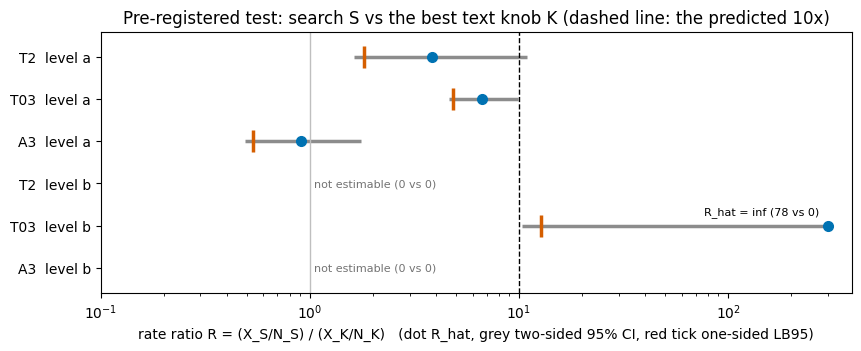

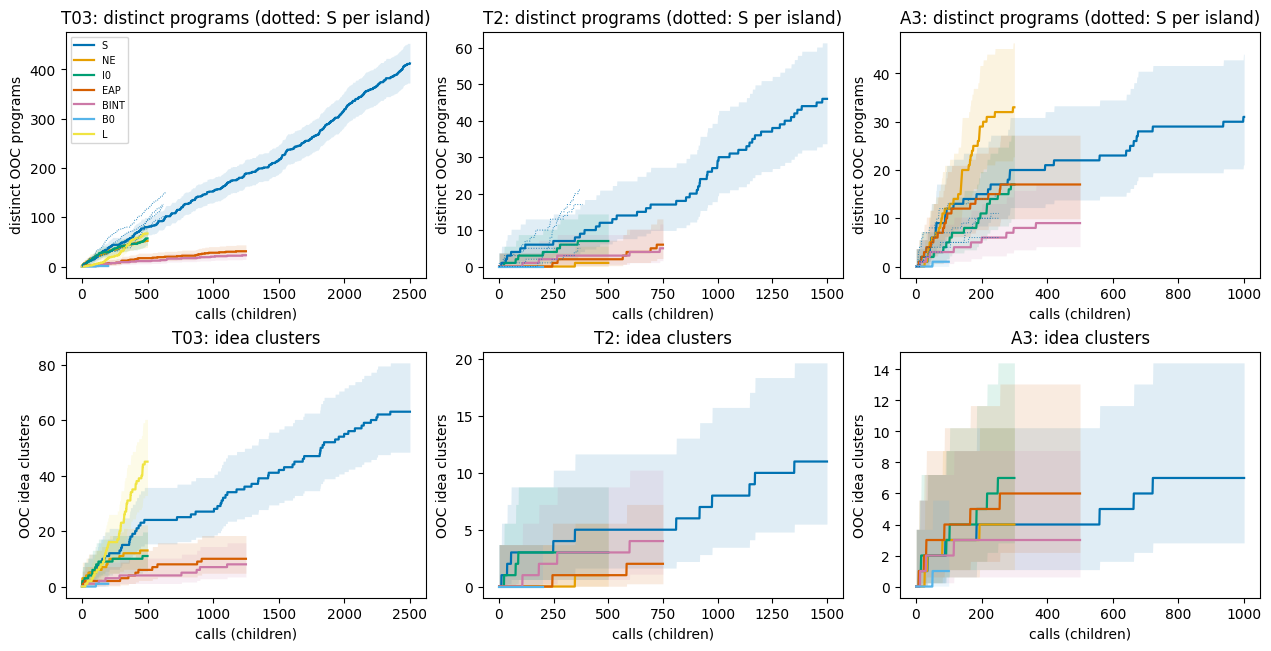

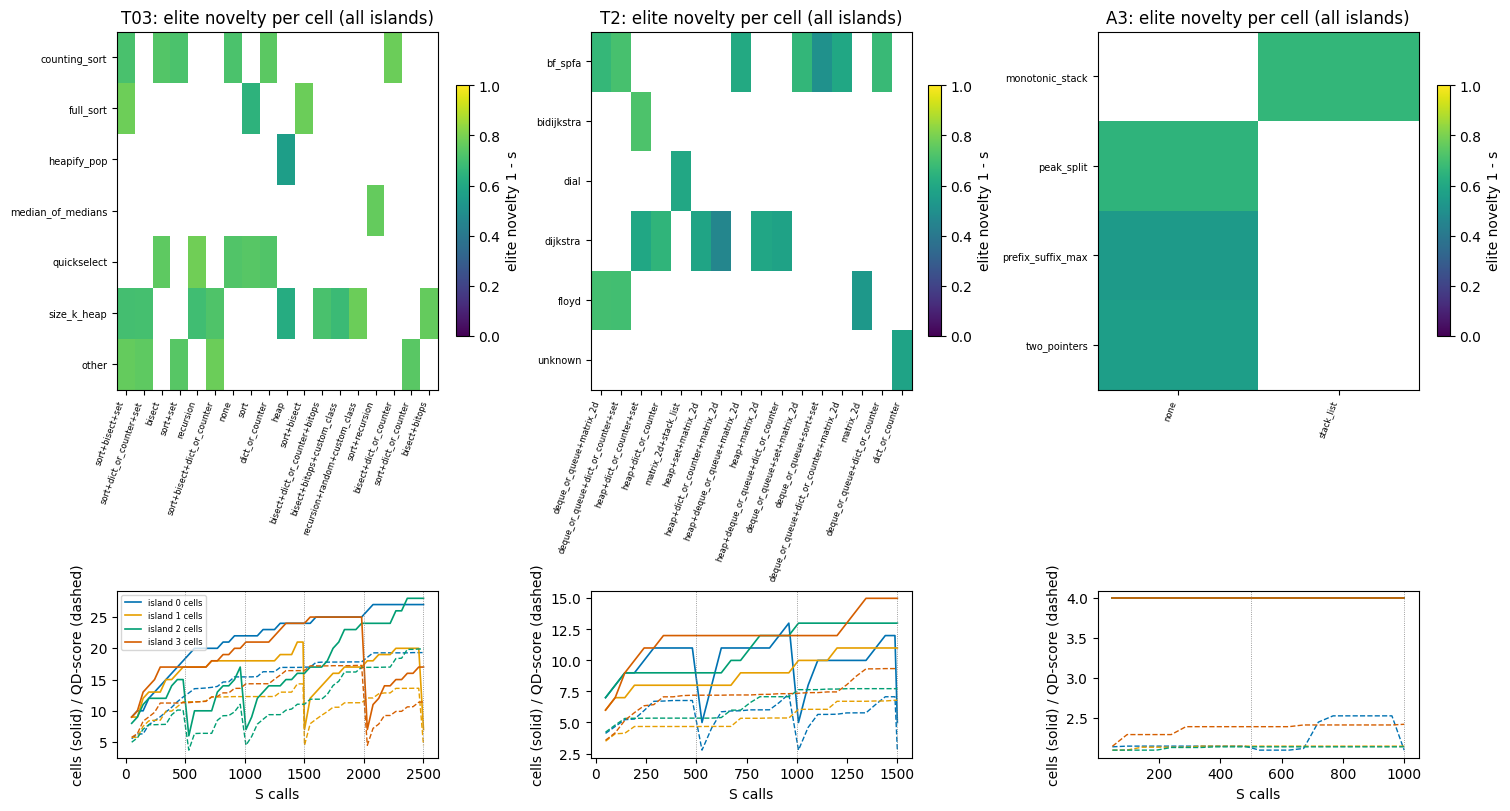

In [34]:
# ---------------------------------------------------------------- key results: the pre-registered tests
lv = res["ratio_tests"]["levels"]
fmt = lambda x: "-" if x is None else ("inf" if x == math.inf else f"{x:.2f}")  # noqa: E731
print(f"{'task':<5}{'level':<6}{'K':<6}{'X_S/N_S':>10}{'X_K/N_K':>10}{'R_hat':>8}{'LB95':>8}{'95% CI':>16}  verdict")
for L in ("a", "b"):
    for t, v in lv[L]["per_task"].items():
        ci = "-" if v["CI95"][0] is None else f"{fmt(v['CI95'][0])}-{fmt(v['CI95'][1])}"
        print(f"{t:<5}{L:<6}{v['K_arm']:<6}{v['X_S']:>5}/{v['N_S']:<4}{v['X_K']:>5}/{v['N_K']:<4}{fmt(v['R_hat']):>8}"
              f"{fmt(v['LB95']):>8}{ci:>16}  {v['verdict']}")
print(f"OVERALL: level a {lv['a']['overall']}, level b {lv['b']['overall']}  "
      f"(prediction: S >= 10x K on >= 2 tasks; NOVEL programs: {claim['n_novel_programs']}, rule of three "
      f"<= {claim['rule_of_three_over_clusters']:.1%} over {claim['n_adjudicated_clusters']} adjudicated clusters)")
print("\nsecondary contrasts on T03 at level b:")
for k, v in lv["b"]["per_task"]["T03"]["secondary"].items():
    print(f"   {k:<14} {v['X_S']:>3}/{v['N_S']:<5} vs {v['X_K']:>3}/{v['N_K']:<5} R_hat {fmt(v['R_hat']):>6}  LB95 {fmt(v['LB95'])}")
t_b = res["L_vs_S"]["test_b"]
print(f"   L vs S(first 500)  {t_b['X_S']} vs {t_b['X_K']}  R_hat {fmt(t_b['R_hat'])}  LB95 {fmt(t_b['LB95'])}")
print(f"\n{'task':<5}{'arm':<6}{'N':>6}{'correct':>9}{'X_a':>6}{'rate_a':>8}{'X_b':>5}{'clusters_a':>12}")
for t in tasks:
    for a in ARMS + ("L",):
        v = res["arm_rates"][t].get(a) if a != "L" else (res["L_vs_S"]["L"] if t == "T03" else None)
        vb = res["arm_rates_b"][t].get(a) if a != "L" else v
        if v and v["N"]:
            print(f"{t:<5}{a:<6}{v['N']:>6}{v['correct']:>9}{v['X_a']:>6}{v['rate_a']:>8.3f}{vb['X_b']:>5}{v['clusters_a']:>12}")

# forest plot of the primary test (notebook addition)
fig, ax = plt.subplots(figsize=(8.5, 3.4), layout="constrained")
fp = [(f"{t}  level {L}", v) for L in ("a", "b") for t, v in lv[L]["per_task"].items()]
CAP = 300.0
for i, (name, v) in enumerate(fp):
    if not v["estimable"]:
        ax.text(1.05, i, "not estimable (0 vs 0)", va="center", fontsize=8, color="0.45")
        continue
    lo, hi = v["CI95"]
    ax.plot([max(lo, 0.1), min(hi, CAP)], [i, i], color="0.55", lw=2.5, solid_capstyle="butt")
    ax.plot([v["LB95"]], [i], marker="|", ms=16, mew=2.5, color="#D55E00")
    r = min(v["R_hat"], CAP)
    ax.plot([r], [i], "o", color="#0072B2", ms=7)
    if v["R_hat"] == math.inf:
        ax.annotate("R_hat = inf (78 vs 0)", (CAP, i), xytext=(-6, 8), textcoords="offset points", ha="right", fontsize=8)
ax.axvline(10, ls="--", color="k", lw=1)
ax.axvline(1, color="0.75", lw=1)
ax.set_xscale("log")
ax.set_xlim(0.1, CAP * 1.3)
ax.set_yticks(range(len(fp)), [n for n, _ in fp])
ax.set_ylim(len(fp) - 0.4, -0.6)   # first row on top, padded
ax.set_xlabel("rate ratio R = (X_S/N_S) / (X_K/N_K)   (dot R_hat, grey two-sided 95% CI, red tick one-sided LB95)")
ax.set_title("Pre-registered test: search S vs the best text knob K (dashed line: the predicted 10x)")
plt.show()

# ---------------------------------------------------------------- figure helpers and F1, F2 of src/figures.py
PALETTE = ("#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000")
FIG_ARMS = ("S", "NE", "I0", "EAP", "BINT", "B0", "L")   # figures.ARMS, renamed (analysis.ARMS has no arm L)
ARM_COLOR = {a: PALETTE[i % len(PALETTE)] for i, a in enumerate(FIG_ARMS)}
CLASS_COLOR = {"NOVEL ALGORITHM": "#D55E00", "KNOWN OUTSIDE CATALOGUE": "#0072B2", "CATALOGUE VARIANT": "#999999",
               "DEGENERATE": "#000000", None: "#CCCCCC"}


def _legend(ax, **kw) -> None:
    ax.legend(**kw)


def _save(fig, name: str) -> None:
    for ax in fig.axes:  # notebook stand-in for the house-style fit_titles(): wrap long panel titles
        if len(ax.get_title()) > 48:
            ax.set_title(textwrap.fill(ax.get_title(), 48), fontsize=9)
    FIGS.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGS / f"{name}.png", dpi=150)
    plt.show()           # notebook: shown inline (the original wrote PDF + PNG and closed the figure)
    plt.close(fig)


def _poisson_band(c: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    lo = np.where(c > 0, stats.chi2.ppf(0.025, 2 * c) / 2, 0.0)
    hi = stats.chi2.ppf(0.975, 2 * c + 2) / 2
    return lo, hi


def f1(samples, tasks) -> None:
    curves = read_json(RESULTS / "discovery_curves.json")
    fig, axes = plt.subplots(2, len(tasks), figsize=(4.2 * len(tasks), 6.4), layout="constrained", squeeze=False)
    for j, t in enumerate(tasks):
        for i, key in enumerate(("distinct", "clusters")):
            ax = axes[i][j]
            for a in FIG_ARMS:
                y = np.array(curves[key].get(t, {}).get(a) or [])
                if a == "L":
                    rs = sorted([r for r in samples if r["task"] == t and r["arm"] == "L"], key=lambda r: r["slot"])
                    seen: set = set()
                    y = []
                    for r in rs:
                        if r.get("correct") and r.get("ooc_screen") and r.get("distinct_id" if key == "distinct" else
                                                                             "cluster_id"):
                            seen.add(r["distinct_id" if key == "distinct" else "cluster_id"])
                        y.append(len(seen))
                    y = np.array(y)
                if len(y) == 0:
                    continue
                x = np.arange(1, len(y) + 1)
                lo, hi = _poisson_band(y.astype(float))
                ax.plot(x, y, color=ARM_COLOR[a], label=a, lw=1.6)
                ax.fill_between(x, lo, hi, color=ARM_COLOR[a], alpha=0.12, lw=0)
            if key == "distinct":
                isl = defaultdict(list)
                for r in sorted([r for r in samples if r["task"] == t and r["arm"] == "S"], key=lambda r: r["slot"]):
                    isl[r.get("island")].append(r)
                for k, rs in isl.items():
                    seen = set()
                    y = []
                    for r in rs:
                        if r.get("correct") and r.get("ooc_screen") and r.get("distinct_id"):
                            seen.add(r["distinct_id"])
                        y.append(len(seen))
                    ax.plot(np.arange(1, len(y) + 1), y, color=ARM_COLOR["S"], lw=0.7, ls=":", alpha=0.8)
            ax.set_xlabel("calls (children)")
            ax.set_ylabel("distinct OOC programs" if key == "distinct" else "OOC idea clusters")
            ax.set_title(f"{t}: {'distinct programs (dotted: S per island)' if key == 'distinct' else 'idea clusters'}")
            if j == 0 and i == 0:
                _legend(ax, loc="upper left", fontsize=7)
    _save(fig, "F1_discovery_curves")


def f2(tasks) -> None:
    fig, axes = plt.subplots(2, len(tasks), figsize=(5.0 * len(tasks), 8.0), layout="constrained", squeeze=False,
                             gridspec_kw={"height_ratios": [3, 1.4]})
    for j, t in enumerate(tasks):
        p = RESULTS / f"archive_{t}.json"
        if not p.exists():
            continue
        a = read_json(p)
        best: dict[tuple[str, str], float] = {}
        for isl in a["final"]["islands"]:
            for c, e in isl["cells"].items():
                lab, sig = c.split("|", 1)
                best[(lab, sig)] = max(best.get((lab, sig), 0.0), e["novelty"])
        labs = sorted({k[0] for k in best}, key=lambda x: (x == "other", x))
        sigs = sorted({k[1] for k in best}, key=lambda s: -sum(1 for k in best if k[1] == s))[:18]
        M = np.full((len(labs), len(sigs)), np.nan)
        for (l, s), v in best.items():
            if s in sigs:
                M[labs.index(l), sigs.index(s)] = v
        ax = axes[0][j]
        im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=1)
        ax.set_yticks(range(len(labs)), labs, fontsize=7)
        ax.set_xticks(range(len(sigs)), sigs, rotation=70, ha="right", fontsize=6)
        ax.set_title(f"{t}: elite novelty per cell (all islands)")
        fig.colorbar(im, ax=ax, shrink=0.7, label="elite novelty 1 - s")
        ax2 = axes[1][j]
        hist = a.get("history") or []
        if hist:
            tt = [h["t"] for h in hist]
            for k in range(len(hist[0]["n_cells"])):
                ax2.plot(tt, [h["n_cells"][k] for h in hist], color=PALETTE[k % len(PALETTE)], lw=1.2,
                         label=f"island {k} cells")
                ax2.plot(tt, [h["qd_score"][k] for h in hist], color=PALETTE[k % len(PALETTE)], lw=1.0, ls="--")
            for h in hist:
                for rr in h.get("resets") or []:
                    ax2.axvline(rr["at_call"], color="0.5", lw=0.6, ls=":")
        ax2.set_xlabel("S calls")
        ax2.set_ylabel("cells (solid) / QD-score (dashed)")
        if j == 0:
            _legend(ax2, loc="upper left", fontsize=6)
    _save(fig, "F2_archive_heatmaps")


FIG_TASKS = [t for t in ("T03", "T2", "A3") if t in tasks]   # make_all's order
with warnings.catch_warnings():     # as in figures.make_all
    warnings.simplefilter("ignore")
    f1(samples, FIG_TASKS)
    f2(FIG_TASKS)

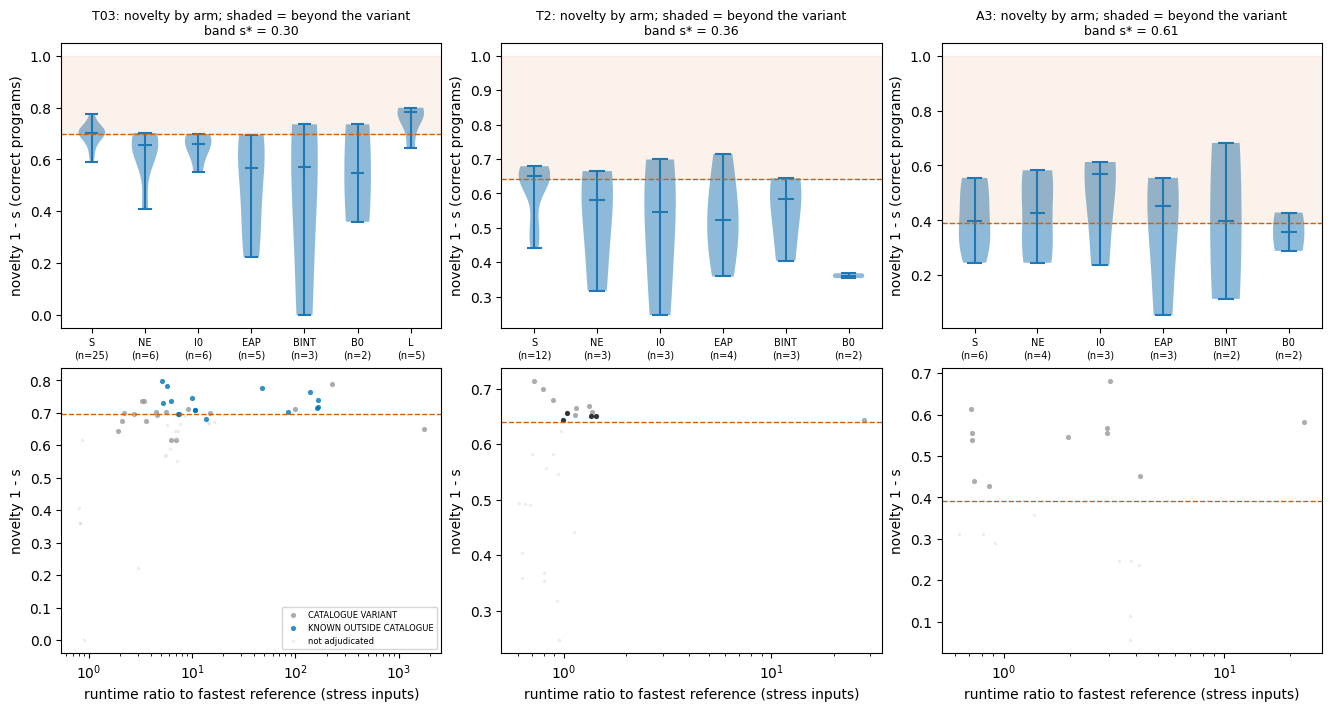

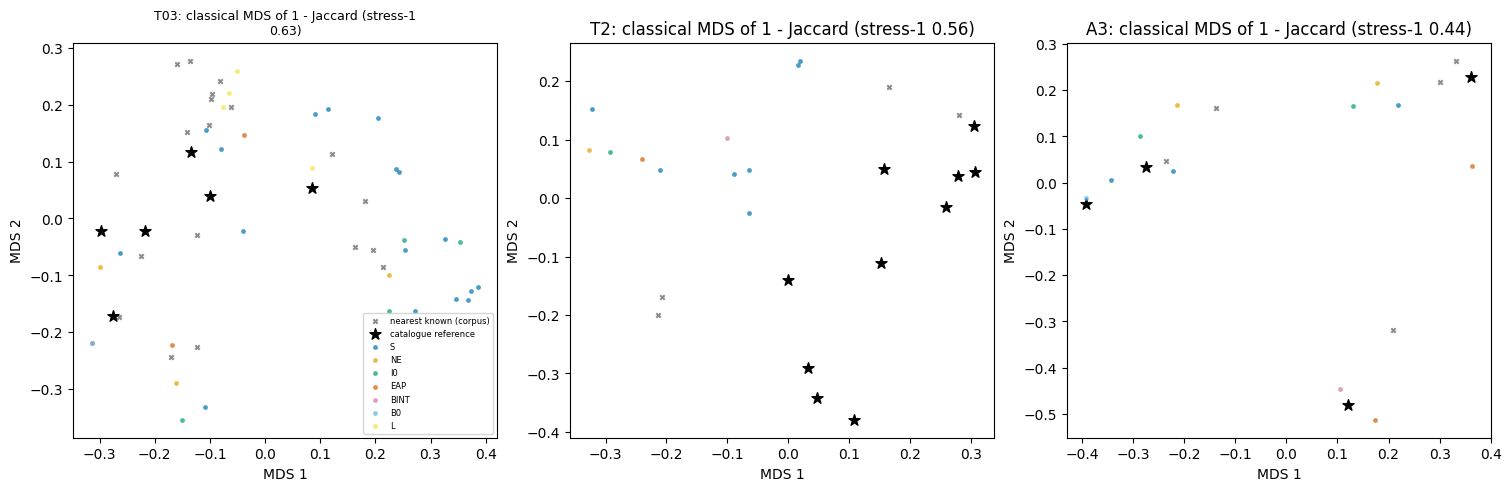

program-space MDS of the replayed programs: {'T03': {'n_programs': 32, 'n_refs': 6, 'n_known': 19, 'stress1': 0.6292875131177095}, 'T2': {'n_programs': 11, 'n_refs': 10, 'n_known': 4, 'stress1': 0.5620724761901373}, 'A3': {'n_programs': 11, 'n_refs': 4, 'n_known': 5, 'stress1': 0.44270200252585873}}
the run's MDS over all distinct OOC programs: {'T03': {'n_programs': 360, 'n_refs': 6, 'n_known': 86, 'stress1': 0.621172213163349}, 'T2': {'n_programs': 65, 'n_refs': 10, 'n_known': 12, 'stress1': 0.5609076163086242}, 'A3': {'n_programs': 108, 'n_refs': 4, 'n_known': 21, 'stress1': 0.48679457929556286}}

files written under demo_run/: ['commitments.log', 'data/corpus/ast_seqs.json', 'data/corpus/codes.jsonl', 'data/corpus/meta.jsonl', 'data/corpus/shingles.npz', 'data/corpus/summary.json', 'data/corpus/type_codes.json', 'data/labels_final.jsonl', 'data/rows_A3.jsonl', 'data/rows_T03.jsonl', 'data/rows_T2.jsonl', 'data/rows_calib.jsonl', 'data/seeds_A3.json', 'data/seeds_T03.json', 'data/se

In [35]:
# ---------------------------------------------------------------- F3 and F6 of src/figures.py on the replayed programs
def f3(samples, tasks) -> None:
    plan = read_json(PRED / "commit1.json")
    fig, axes = plt.subplots(2, len(tasks), figsize=(4.4 * len(tasks), 7.0), layout="constrained", squeeze=False)
    for j, t in enumerate(tasks):
        ax = axes[0][j]
        data, names = [], []
        for a in FIG_ARMS:
            v = [r["novelty"] for r in samples if r["task"] == t and r["arm"] == a and r.get("correct") and
                 r.get("novelty") is not None]
            if v:
                data.append(v)
                names.append(f"{a}\n(n={len(v)})")
        if data:
            parts = ax.violinplot(data, showmedians=True)
            for k, b in enumerate(parts["bodies"]):
                b.set_alpha(0.5)
            ax.set_xticks(range(1, len(names) + 1), names, fontsize=7)
        ss = plan["s_star"][t]["s_star"]
        ax.axhspan(1 - ss, 1.0, color="#D55E00", alpha=0.08)
        ax.axhline(1 - ss, color="#D55E00", lw=1, ls="--")
        ax.set_ylabel("novelty 1 - s (correct programs)")
        ax.set_title(f"{t}: novelty by arm; shaded = beyond the variant band s* = {ss:.2f}")
        ax = axes[1][j]
        pts = [r for r in samples if r["task"] == t and r.get("correct") and r.get("novelty") is not None and
               r.get("runtime_ratio")]
        for cls in ("CATALOGUE VARIANT", "DEGENERATE", "KNOWN OUTSIDE CATALOGUE", "NOVEL ALGORITHM", None):
            xs = [r["runtime_ratio"] for r in pts if r.get("final_class") == cls]
            ys = [r["novelty"] for r in pts if r.get("final_class") == cls]
            if xs:
                ax.scatter(xs, ys, s=6 if cls is None else 14, color=CLASS_COLOR[cls], alpha=0.35 if cls is None else 0.8,
                           label=cls or "not adjudicated", lw=0)
        ax.set_xscale("log")
        ax.axhline(1 - ss, color="#D55E00", lw=1, ls="--")
        ax.set_xlabel("runtime ratio to fastest reference (stress inputs)")
        ax.set_ylabel("novelty 1 - s")
        if j == 0:
            _legend(ax, loc="lower right", fontsize=6)
    _save(fig, "F3_novelty")


def classical_mds(D: np.ndarray, k: int = 2) -> tuple[np.ndarray, float]:
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    idx = np.argsort(w)[::-1][:k]
    X = V[:, idx] * np.sqrt(np.maximum(w[idx], 0))
    Dh = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
    stress = float(np.sqrt(((D - Dh) ** 2).sum() / max((D ** 2).sum(), 1e-12)))
    return X, stress


def f6(samples, tasks) -> None:
    C = Critic()
    fig, axes = plt.subplots(1, len(tasks), figsize=(5.0 * len(tasks), 4.8), layout="constrained", squeeze=False)
    rng = np.random.default_rng(3)
    out = {}
    for j, t in enumerate(tasks):
        ax = axes[0][j]
        progs = [r for r in samples if r["task"] == t and r.get("correct") and r.get("ooc_screen") and
                 r.get("is_first_of_distinct")]
        if len(progs) > MDS_MAX_PROGRAMS:
            progs = [progs[i] for i in sorted(rng.choice(len(progs), MDS_MAX_PROGRAMS, replace=False))]
        refs = load_task(t)["references"]
        id2idx = {m["id"]: k for k, m in enumerate(C.meta)}
        near = sorted({id2idx[r["nearest_known_id"]] for r in progs if r.get("nearest_known_id") in id2idx
                       and C.meta[id2idx[r["nearest_known_id"]]]["kind"] == "corpus"})[:120]
        codes = [r["code"] for r in progs] + list(refs.values()) + [C.code(i) for i in near]
        kinds = [r["arm"] for r in progs] + ["catalogue"] * len(refs) + ["known"] * len(near)
        if len(codes) < 4:
            ax.set_axis_off()
            continue
        M = to_matrix([shingle_ids(c) for c in codes])
        inter = (M @ M.T).toarray()
        sz = np.diag(inter)
        den = sz[:, None] + sz[None, :] - inter
        Jm = np.where(den > 0, inter / np.maximum(den, 1e-9), 1.0)
        X, stress = classical_mds(1 - Jm)
        for kind in ("known", "catalogue") + FIG_ARMS:
            ii = [i for i, k in enumerate(kinds) if k == kind]
            if not ii:
                continue
            if kind == "known":
                ax.scatter(X[ii, 0], X[ii, 1], s=10, marker="x", color="0.55", label="nearest known (corpus)")
            elif kind == "catalogue":
                ax.scatter(X[ii, 0], X[ii, 1], s=70, marker="*", color="#000000", label="catalogue reference")
            else:
                ax.scatter(X[ii, 0], X[ii, 1], s=12, color=ARM_COLOR[kind], alpha=0.7, label=kind, lw=0)
        ax.set_title(f"{t}: classical MDS of 1 - Jaccard (stress-1 {stress:.2f})")
        ax.set_xlabel("MDS 1")
        ax.set_ylabel("MDS 2")
        if j == 0:
            _legend(ax, loc="best", fontsize=6)
        out[t] = {"n_programs": len(progs), "n_refs": len(refs), "n_known": len(near), "stress1": stress}
    _save(fig, "F6_program_space_mds")
    write_json(RESULTS / "mds.json", out)


with warnings.catch_warnings():     # as in figures.make_all
    warnings.simplefilter("ignore")
    f3(replayed, FIG_TASKS)
    f6(replayed, FIG_TASKS)
print("program-space MDS of the replayed programs:", read_json(RESULTS / "mds.json"))
print("the run's MDS over all distinct OOC programs:", data["published"]["mds"])
print(f"\nfiles written under {ROOT.name}/:", sorted(p.relative_to(ROOT).as_posix() for p in ROOT.rglob("*") if p.is_file()))

## Summary

- **The prediction failed.** S ≥ 10× K on ≥ 2 tasks: NOT MET at level a on all three tasks (R̂ 3.83, 6.65, 0.91). At level b, only T03 has any out-of-catalogue program: S 78 vs EAP 0 (STRONG); T2 and A3 are NOT ESTIMABLE (0 vs 0). The overall verdict is NOT MET at both levels.
- **Evolution helps a little, but only towards known techniques.** On T03, S beats the no-evolution ablation at level b (78 vs 0), and the lineages compose across generations (see the depth-4 treap above). But every OOC program is a nameable textbook technique: value-range binary search, Fenwick-tree or treap order statistics, bucket select. No NOVEL algorithm was found. Banning the catalogue made the 8B model **substitute** a known algorithm, not invent one.
- **The critic can be gamed.** On T2, the OOC lead is restyled SPFA. One search program passes every hidden and stress test yet is wrong in general; the counterexample run in the sandbox above shows it.
- **Every number re-derives from the shipped records.** Section 15 reports how many published values are reproduced exactly.

**Scaling this demo.**
- `N_PROGRAMS = 99` replays every shipped call.
- `PLACEBO_REPS = 200`, `BOOTSTRAP_REPS = 2000` and `MDS_MAX_PROGRAMS = 360` are the original settings.

**The full experiment** needs the original repository folder, a 20 GB GPU and OpenRouter keys. `reproducibility.md` lists every step: `method.py --stage inputs | corpus | tests | commit0 | calib | commit1 | base | run | L | label | adjudicate | classes | analyse | outputs`.